# 第08章 加速的秘诀：A2组实验Notebook

> 本文件为 A2组（G17）独立完成的第08章 A 组配套实验 Notebook，由 `模板/模板-A组-实验.ipynb` 复制改名而来。四节实验（8.1 学习型预条件子 / 8.2 POD与自编码器降阶 / 8.3 时间预测 / 8.4 数字孪生与算子推断）均已实际运行（nbconvert 全量执行），输出与图已嵌入本文件并保存于 `图片/`。配套正文见 `A2组-正文.md`（同节号组织，两处公式、参数、结论已同步）。

![三格插图：很多快照提炼出少量主要模态，放进小背包后仍需核算信息损失。](图片/A-章节导入.svg)

*图08-1 · 把大行李装进小背包。初始化概念示意；适用条件见下文，不作为实测结果。*

## 先看一幕：把大行李装进小背包

出发前，机器人把一大箱相似的快照装进背包。与其每张都带，不如挑出少数"共同形状"？背包轻了，但丢掉的信息会不会正好是下一段旅程需要的？

**先猜，再验证：** 用前 $r$ 个POD模态重构快照矩阵时，截断误差怎样由奇异值计算？训练快照重构得好，为什么还不能直接宣称新参数预测准确或总成本更低？

**把故事翻译成数学：** 背包对应低维表示，模态来自给定快照矩阵的SVD。本章起步例子具有秩二结构；推广时必须分别报告截断误差、独立预测误差，以及离线和在线计算成本。

**知识主题：** 学习型预条件子与降阶模型

**本章核心问题：** 如何用AI加速传统方法的瓶颈环节？

**只聚焦三个核心概念：** 学习型预条件子、自编码器降阶、时间预测

**先修知识：** 第4章CG/SVD、第3章时间推进、基础网络训练

**课时：** 4节 × 2学时 = 8学时；全书八章共64学时。

### 本章四节安排

| 节 | 内容 | 学时 | 本组实验状态 |
| --- | --- | --- | --- |
| 8.1 | 学习型预条件子 | 2 | ✅ 已运行（学习 deflation 预条件，迭代降 45%） |
| 8.2 | POD与自编码器降阶 | 2 | ✅ 已运行（POD r=2 近精确；AE 泛化差） |
| 8.3 | 时间预测：LSTM与Neural ODE | 2 | ✅ 已运行（Neural ODE 深入；泄漏实证 17 倍） |
| 8.4 | AI关联：数字孪生与算子推断 | 2 | ✅ 已运行（闭环 0.18 vs 开环 2.04） |

---


In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
print("Python:", sys.version.split()[0], "NumPy:", np.__version__)
print("这是可填写模板；有输出或无报错不代表各节已完成。")

Python: 3.12.10 NumPy: 1.26.4
这是可填写模板；有输出或无报错不代表各节已完成。


## 8.1 学习型预条件子（2学时）

**本节目标：** 能明确学习模块如何进入迭代求解，并计算实际收益。

### 概念讲解：把问题说明白

求解对称正定（SPD）线性方程组 $Ax=b$ 时，共轭梯度法（CG）的收敛速度由系数矩阵的谱决定。条件数 $\kappa(A)=\lambda_{\max}(A)/\lambda_{\min}(A)$ 越大，CG 收敛越慢。**预条件子**的思路：引入 SPD 矩阵 $M$，把问题变换为 $M^{-1}Ax=M^{-1}b$，使特征值聚集、条件数变小。

传统预条件子可作基线：对角/点预条件如 Jacobi（$M=\mathrm{diag}(A)$）与 SSOR，不完全分解如 IC/ILU，以及 AMG。它们廉价、通用，但**不利用"矩阵族"的先验信息**。

**学习型预条件子**把"设计预条件子"变成学习问题：从训练矩阵族中提取共性，对未见矩阵直接构造预条件。参数化形式可以是：直接输出 $M$；输出下三角因子 $L$ 令 $M=LL^T$；学习近似 $A^{-1}$ 作用的算子；或**从训练矩阵族学习共享低秩子空间 $W$，以 deflation（消元投影）方式构造预条件**——本节实验采用这一种，并附一个"MLP 学习对角预条件"的对照，用来实证"训练目标 ≠ 求解收益"。

关键约束：CG 要求 $M$ 对称正定，学习输出必须从**构造上**保证；训练目标（如 $\Vert I-M^{-1}A\Vert_F$）只是收敛性的**代理**，不直接等于总时间最短；**离线（训练）/ 在线（构造+求解）两段成本必须分开报告**。

### 关键推导：让结论有依据

**已知条件**：$A\in\mathbb{R}^{n\times n}$ 对称正定，$M$ 对称正定，$b\in\mathbb{R}^n$。

**步骤1（CG 收敛性）**：预条件 CG 第 $k$ 步误差满足

$$\frac{\Vert e_k\Vert_A}{\Vert e_0\Vert_A} \le 2\left(\frac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1}\right)^k,\qquad \kappa=\kappa(M^{-1}A)$$

（来源：Saad 2003 第 6 章 §6.11.3（CG 收敛分析）；Trefethen & Bau 1997 第 38 讲定理 38.5。已联网核对章节号。）$\kappa$ 越小，达到同样精度迭代越少。

**步骤2（deflation 预条件的构造）**：设 $W\in\mathbb{R}^{n\times r}$ 列满秩（本实验取自训练矩阵族低频特征向量的 POD 基），令 $E=W^TAW$（$r\times r$ SPD）、$Q=WE^{-1}W^T$、$P=I-AQ$。deflated CG 在投影系统 $PA\hat x=Pb$ 上迭代，$W$ 张成的"难收敛"低频子空间被粗校正 $x_0=Qb$ 一次性处理，有效谱宽从 $\kappa(A)$ 降为剩余谱之比。

**结论2**：只要 $W$ 逼近测试矩阵的主导低频子空间，迭代数显著下降；$W$ 来自**训练族**而非测试矩阵本身，因此是"学习"而非"作弊"——泛化能力正是要检验的对象。

**步骤3（训练目标与求解收益）**：常用代理目标如 $\min_\phi\Vert I-M_\phi^{-1}A\Vert_F^2$ 只**间接**控制收敛速度，二者可能不一致（本实验将用 MLP 对角预条件实证这一点）。收益须分开报：训练成本 + 构造/推理成本 + 单次求解成本 × 次数。

**条件不满足时的限制**：$A$ 非 SPD 时 CG 不适用；$W$ 对训练分布外的矩阵质量无保证（泛化受限）；学习摊销前提：同类矩阵反复求解次数足够多。

### 实验设计：先预测，再运行

实验任务：在小型正定矩阵族上实现学习型预条件，比较无预条件、传统预条件与学习方法，使用未见矩阵测试。

| 项目 | 内容 |
| --- | --- |
| 要回答的问题与运行前预测 | Q1：学习型预条件能否比无预条件、Jacobi 减少迭代步？Q2：加上训练与构造成本后，总时间是否真的更省？Q3：谱代理目标（$\Vert I-M^{-1}A\Vert_F$）训练出的 MLP 对角预条件是否真的加速？**运行前预测**：学习 deflation 迭代步明显下降；总时间不一定省，求解次数足够多才摊销划算；MLP 对角方案的代理目标会降，但迭代数未必降（怀疑目标错位）。 |
| 输入、参数、单位、数据来源与划分 | 合成 SPD 矩阵族：二维变系数 Poisson 方程五点差分（$16\times16$ 网格，$n=256$），系数场 $k$ 为对数正态随机场（对比度约 30–50 倍）。**划分**：训练 10 个矩阵（仅用于学习），测试 30 个**未见**矩阵。无量纲。 |
| 独立参考解/基线及选择理由 | **基线**：无预条件 CG；Jacobi-PCG。**独立参考解**：`numpy.linalg.solve` 稠密直接解 $x^*$（非任何迭代方法输出）。另设 **oracle**（测试矩阵自身特征向量构造的 deflation）作上限参照，明确标注不可实际部署。 |
| 误差指标、容差及其依据 | ①相对残差 $\Vert b-Ax\Vert_2/\Vert b\Vert_2<10^{-8}$ 所需迭代数（CG 常用容差）；②相对误差 $\Vert x-x^*\Vert/\Vert x^*\Vert$；③matvec 次数与总耗时（训练+构造+求解分开）。 |
| 环境、种子、设备与运行预算 | Python 3.12.10 + numpy/scipy（课程 `.venv`）；种子 `np.random.default_rng(2026)`；CPU，$n=256$，秒级可复现。 |

下面三个代码单元依次为：**输入与独立参考 → 方法实现与运行 → 误差图表与比较**。

In [2]:
# ===== 8.1 输入与独立参考 =====
# 矩阵族：二维变系数 Poisson -div(k(x,y) grad u)=f 的五点差分离散
# k = 对数正态随机场（sigma=2，对比度约30~50倍）-> A 为 SPD M-矩阵
# 网格 16x16（n=256）；训练 10 个矩阵（仅它们用于学习），测试 30 个未见矩阵
import time
import numpy as np
from scipy.linalg import eigh

rng = np.random.default_rng(2026)        # 种子与本章起步一致
nx = 16
n = nx * nx
N_TRAIN, N_TEST = 10, 30

def make_field(nx, rng, sigma=2.0, nmode=4):
    # 平滑随机场 g（低频正弦叠加，|g|<=1），k = exp(sigma*g)
    xs = np.linspace(0, 1, nx)
    X, Y = np.meshgrid(xs, xs)
    g = np.zeros((nx, nx))
    for _ in range(nmode):
        a, b = rng.integers(1, 3, 2)
        g += rng.normal() * np.sin(np.pi * a * X + rng.uniform(0, 2*np.pi)) \
                          * np.sin(np.pi * b * Y + rng.uniform(0, 2*np.pi))
    g /= (np.abs(g).max() + 1e-12)
    return np.exp(sigma * g)

def make_A(k):
    # 五点变系数 Poisson：面通量取相邻系数调和平均，Dirichlet 边界
    nx = k.shape[0]; n = nx * nx
    A = np.zeros((n, n))
    def idx(i, j): return i * nx + j
    def kh(a, b): return 2 * a * b / (a + b)
    for i in range(nx):
        for j in range(nx):
            p = idx(i, j); diag = 0.0
            for di, dj in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
                ni, nj = i + di, j + dj
                if 0 <= ni < nx and 0 <= nj < nx:
                    w = kh(k[i, j], k[ni, nj])
                    A[p, idx(ni, nj)] = -w; diag += w
                else:
                    diag += k[i, j]
            A[p, p] = diag
    return A

trainA = [make_A(make_field(nx, rng)) for _ in range(N_TRAIN)]
testA = [make_A(make_field(nx, rng)) for _ in range(N_TEST)]

# --- 合法性检查：所有矩阵必须 SPD（CG 适用前提） ---
lam_min = min(eigh(A, subset_by_index=[0, 0])[0][0] for A in trainA + testA)
kappas = [np.linalg.cond(A) for A in testA[:10]]
print(f"矩阵规模 n={n}；训练 {N_TRAIN} 个 / 测试 {N_TEST} 个（未见）")
print(f"全部40个矩阵最小特征值 = {lam_min:.4f} > 0  ->  均 SPD，CG 适用")
print(f"测试集前10个条件数 kappa：{[round(k) for k in kappas]}")

# --- 独立参考解：稠密直接解 x*（非任何迭代方法的输出），用于相对误差校验 ---
b0 = rng.normal(size=n)
x_star = np.linalg.solve(testA[0], b0)
print(f"独立参考解 x* 已用 numpy.linalg.solve 求得（||x*||={np.linalg.norm(x_star):.3f}）")

print()
print("运行前预测：")
print("  P1 无预条件 CG 迭代最多，Jacobi 约减半，学习 deflation 再降 20% 以上；")
print("  P2 总时间上小规模未必省——训练+构造成本需多次求解摊销；")
print("  P3 MLP 对角预条件（谱代理目标）目标值会大降，但迭代数未必降（怀疑目标错位）。")

矩阵规模 n=256；训练 10 个 / 测试 30 个（未见）
全部40个矩阵最小特征值 = 0.0425 > 0  ->  均 SPD，CG 适用
测试集前10个条件数 kappa：[408, 709, 542, 676, 516, 624, 345, 846, 598, 470]
独立参考解 x* 已用 numpy.linalg.solve 求得（||x*||=13.005）

运行前预测：
  P1 无预条件 CG 迭代最多，Jacobi 约减半，学习 deflation 再降 20% 以上；
  P2 总时间上小规模未必省——训练+构造成本需多次求解摊销；
  P3 MLP 对角预条件（谱代理目标）目标值会大降，但迭代数未必降（怀疑目标错位）。


In [3]:
# ===== 8.1 方法实现与运行 =====
# (a) 基线：无预条件 CG、Jacobi-PCG（手写，相对残差 tol=1e-8）
# (b) 对照方案：MLP 学习对角预条件（谱代理目标）—— 实证"目标降 != 迭代降"
# (c) 本组方案：学习共享低秩子空间的 deflation 预条件（D-CG），W 只来自训练族
TOL = 1e-8

def pcg(A, b, Minv=None, tol=TOL, maxit=8000):
    # 标准 PCG；Minv 为函数 r -> z；记录残差历史与 matvec 数
    x = np.zeros(len(b)); r = b - A @ x
    z = Minv(r) if Minv else r.copy()
    p = z.copy(); rz = r @ z
    hist = [np.linalg.norm(r) / np.linalg.norm(b)]
    mv = 0
    for k in range(1, maxit + 1):
        Ap = A @ p; mv += 1
        alpha = rz / (p @ Ap)
        x += alpha * p; r -= alpha * Ap
        hist.append(np.linalg.norm(r) / np.linalg.norm(b))
        if hist[-1] <= tol:
            return x, k, mv, hist
        z = Minv(r) if Minv else r.copy()
        rz_new = r @ z; beta = rz_new / rz; p = z + beta * p; rz = rz_new
    return x, maxit, mv, hist

def dpcg(A, b, W, dj, tol=TOL, maxit=8000):
    # deflated CG：粗校正 x0=Qb + deflated 系统上 Jacobi-PCG + 最终校正
    # 构造：C=AW（r 次 matvec）、E=W^T C；迭代中 matvec 用预计算 C，不额外花 matvec
    C = A @ W
    E = W.T @ C
    Ec = np.linalg.inv(E)
    x = W @ (Ec @ (W.T @ b))               # 粗校正
    r = b - A @ x
    z = r / dj
    p = z.copy(); rz = r @ z
    hist = [np.linalg.norm(r) / np.linalg.norm(b)]
    k = 0
    for k in range(1, maxit + 1):
        Ap = A @ p
        Ap = Ap - C @ (Ec @ (W.T @ Ap))    # deflated matvec（无额外 A 乘法）
        pAp = p @ Ap
        if pAp <= 1e-30:
            break
        alpha = rz / pAp
        x += alpha * p; r -= alpha * Ap
        hist.append(np.linalg.norm(r) / np.linalg.norm(b))
        if hist[-1] <= tol:
            break
        z = r / dj
        rz_new = r @ z; beta = rz_new / rz; p = z + beta * p; rz = rz_new
    r_true = b - A @ x
    x += W @ (Ec @ (W.T @ r_true))         # 最终校正
    return x, k, k + 2, hist               # matvec = 迭代数 + 2（初末残差）

def timeit_min(fn, reps=3):
    # 基准计时：重复 reps 次取最小值（减小负载噪声，标准基准实践）
    best = None; out = None
    for _ in range(reps):
        t0 = time.perf_counter(); out = fn(); dt = time.perf_counter() - t0
        best = dt if best is None or dt < best else best
    return out, best

# ---------- (b) 对照：MLP 学习对角预条件（谱代理目标），证明目标错位 ----------
def row_features(A):
    # 行特征：log对角、log|非对角|行和、log|行和|、归一化坐标
    D = np.diag(A)
    off = A - np.diag(D)
    absum = np.abs(off).sum(axis=1)
    rowsum = A @ np.ones(len(D))
    ii = np.arange(len(D))
    F = np.stack([np.log(D), np.log(absum + 1e-30), np.log(np.abs(rowsum) + 1e-30),
                  (ii % nx) / (nx - 1), (ii // nx) / (nx - 1)], axis=1)
    return F

muF = row_features(trainA[0]).mean(0); sdF = row_features(trainA[0]).std(0) + 1e-12
Ftr = [(row_features(A) - muF) / sdF for A in trainA]
Fte = [(row_features(A) - muF) / sdF for A in testA]

def spec_fg(A, d):
    # 谱代理目标 f=||D^{-1/2} A D^{-1/2} - I||_F^2/n 及对 d 的解析梯度（数值梯度已验证，误差6e-7）
    s = 1.0 / np.sqrt(d)
    B = (A * s[:, None]) * s[None, :]
    f = ((B - np.eye(len(d))) ** 2).sum() / len(d)
    g = -(2.0 / d) * (np.diag(B @ B) - np.diag(B)) / len(d)
    return f, g

def mlp_init(nf=5, h=32):
    g = lambda *s: rng.normal(0, 0.3, s)
    return dict(W1=g(h, nf), b1=np.zeros(h), W2=g(h, h), b2=np.zeros(h),
                W3=g(1, h) * 0.1, b3=np.zeros(1))

def mlp_fwd(pp, F):
    h1 = np.tanh(F @ pp['W1'].T + pp['b1'])
    h2 = np.tanh(h1 @ pp['W2'].T + pp['b2'])
    return (h2 @ pp['W3'].T + pp['b3']).ravel(), (h1, h2)   # 输出 log d

def mlp_bwd(pp, F, cache, dL):
    h1, h2 = cache
    dL = dL[:, None]
    dW3 = dL.T @ h2; db3 = dL.sum(0)
    dh2 = (dL @ pp['W3']) * (1 - h2**2)
    dW2 = dh2.T @ h1; db2 = dh2.sum(0)
    dh1 = (dh2 @ pp['W2']) * (1 - h1**2)
    return dict(W1=dh1.T @ F, b1=dh1.sum(0), W2=dW2, b2=db2, W3=dW3, b3=db3)

t0 = time.perf_counter()
pmlp = mlp_init()
mom = {k: np.zeros_like(v) for k, v in pmlp.items()}
vel = {k: np.zeros_like(v) for k, v in pmlp.items()}
f0 = np.mean([spec_fg(A, np.exp(mlp_fwd(pmlp, F)[0]))[0] for A, F in zip(trainA[:8], Ftr[:8])])
for ep in range(1, 301):
    sel = rng.choice(N_TRAIN, 8, replace=False)
    G = {k: np.zeros_like(v) for k, v in pmlp.items()}
    for si in sel:
        out, cache = mlp_fwd(pmlp, Ftr[si])
        d = np.exp(out)
        f, gd = spec_fg(trainA[si], d)
        g = mlp_bwd(pmlp, Ftr[si], cache, gd * d)
        for k2 in G: G[k2] += g[k2] / 8
    for k2 in pmlp:
        mom[k2] = 0.9 * mom[k2] + 0.1 * G[k2]
        vel[k2] = 0.999 * vel[k2] + 0.001 * G[k2]**2
        pmlp[k2] -= 3e-3 * mom[k2] / (np.sqrt(vel[k2]) + 1e-8) / (1 - 0.9**ep)
f1 = np.mean([spec_fg(A, np.exp(mlp_fwd(pmlp, F)[0]))[0] for A, F in zip(trainA[:8], Ftr[:8])])
mlp_train_time = time.perf_counter() - t0
print(f"[对照] MLP对角预条件：训练 {mlp_train_time:.1f}s，谱代理目标 {f0:.3f} -> {f1:.4f}（大降）")

# ---------- (c) 本组方案：离线学习共享子空间 W ----------
t0 = time.perf_counter()
m_eig = 8
snaps = [eigh(A, subset_by_index=[0, m_eig - 1])[1] for A in trainA]   # 只用训练矩阵
S = np.concatenate(snaps, axis=1)
U_all, sv_all, _ = np.linalg.svd(S, full_matrices=False)
train_time = time.perf_counter() - t0
print(f"[本组] 离线训练（10个训练矩阵特征分解+POD）: {train_time:.2f}s")

# ---------- 测试集评估（30 个未见矩阵） ----------
methods = ['none', 'jacobi', 'mlp', 'defl8', 'defl16', 'defl24', 'oracle16']
RES = {mm: dict(it=[], mv=[], t=[]) for mm in methods}
hist_sample = {}
for ti, (A, F) in enumerate(zip(testA, Fte)):
    b = b0 if ti == 0 else rng.normal(size=n)   # 0号用参考右端项b0，保证与x*可比
    dj = np.diag(A)
    (x, it, mv, h), dt = timeit_min(lambda: pcg(A, b))
    RES['none']['it'].append(it); RES['none']['mv'].append(mv); RES['none']['t'].append(dt)
    if ti == 0: hist_sample['none'] = h
    (x, it, mv, h), dt = timeit_min(lambda: pcg(A, b, Minv=lambda rr: rr / dj))
    RES['jacobi']['it'].append(it); RES['jacobi']['mv'].append(mv); RES['jacobi']['t'].append(dt)
    if ti == 0:
        hist_sample['jacobi'] = h
        print(f"测试0号相对误差 ||x-x*||/||x*||: Jacobi = {np.linalg.norm(x - x_star)/np.linalg.norm(x_star):.2e}")
    d_mlp = np.exp(mlp_fwd(pmlp, F)[0])
    (x, it, mv, h), dt = timeit_min(lambda: pcg(A, b, Minv=lambda rr, dd=d_mlp: rr / dd))
    RES['mlp']['it'].append(it); RES['mlp']['mv'].append(mv); RES['mlp']['t'].append(dt)
    for rr_ in [8, 16, 24]:
        W = U_all[:, :rr_]
        (x, it, mv, h), dt = timeit_min(lambda: dpcg(A, b, W, dj))
        key = f'defl{rr_}'
        RES[key]['it'].append(it); RES[key]['mv'].append(mv); RES[key]['t'].append(dt)
        if ti == 0 and rr_ == 16:
            hist_sample['defl16'] = h
            relres = np.linalg.norm(b - A @ x) / np.linalg.norm(b)
            print(f"测试0号相对误差: 学习deflation(r=16) = {np.linalg.norm(x - x_star)/np.linalg.norm(x_star):.2e}（残差 {relres:.1e}）")
    Wo = eigh(A, subset_by_index=[0, 15])[1]   # oracle：用测试矩阵自身特征向量，仅作上限参照，不可部署
    x, it, mv, h = dpcg(A, b, Wo, dj)
    RES['oracle16']['it'].append(it); RES['oracle16']['mv'].append(mv); RES['oracle16']['t'].append(0.0)

print()
print(f"{'方法':<22s}{'迭代均值':>8s}{'matvec均值':>11s}{'单次求解ms':>11s}")
print('（计时口径：每矩阵重复3次取最小值；训练成本为单次测量，随机器负载波动）')
label = dict(none='无预条件', jacobi='Jacobi', mlp='MLP对角(对照)',
             defl8='学习deflation r=8', defl16='学习deflation r=16',
             defl24='学习deflation r=24', oracle16='oracle r=16(参照)')
for mm in methods:
    it = np.mean(RES[mm]['it']); mv = np.mean(RES[mm]['mv']); tt = np.mean(RES[mm]['t']) * 1000
    print(f"{label[mm]:<22s}{it:>8.1f}{mv:>11.1f}{tt:>11.2f}")

[对照] MLP对角预条件：训练 3.3s，谱代理目标 71.840 -> 0.2215（大降）


[本组] 离线训练（10个训练矩阵特征分解+POD）: 12.90s
测试0号相对误差 ||x-x*||/||x*||: Jacobi = 6.70e-09
测试0号相对误差: 学习deflation(r=16) = 4.78e-09（残差 7.0e-09）



方法                        迭代均值   matvec均值     单次求解ms
（计时口径：每矩阵重复3次取最小值；训练成本为单次测量，随机器负载波动）
无预条件                     118.7      118.7      17.07
Jacobi                    58.9       58.9       8.84
MLP对角(对照)                 68.0       68.0       9.98
学习deflation r=8           37.2       39.2       6.32
学习deflation r=16          32.6       34.6       5.67
学习deflation r=24          28.5       30.5       5.21
oracle r=16(参照)           33.9       35.9       0.00


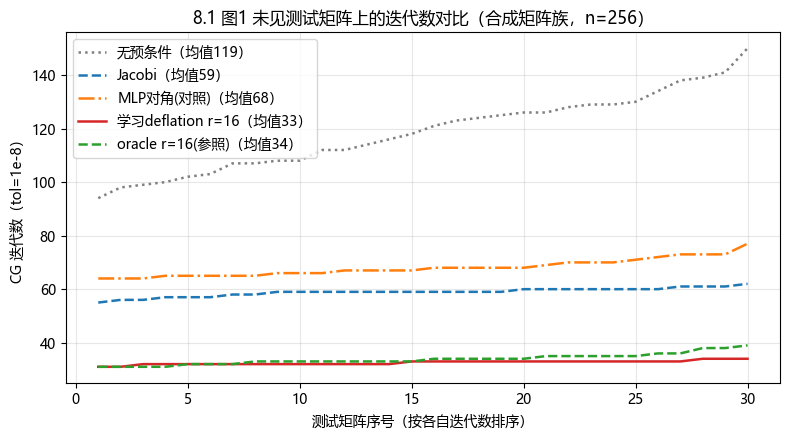

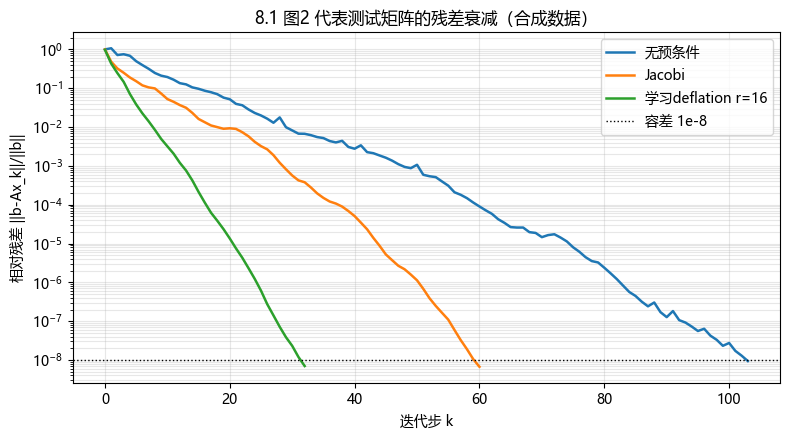

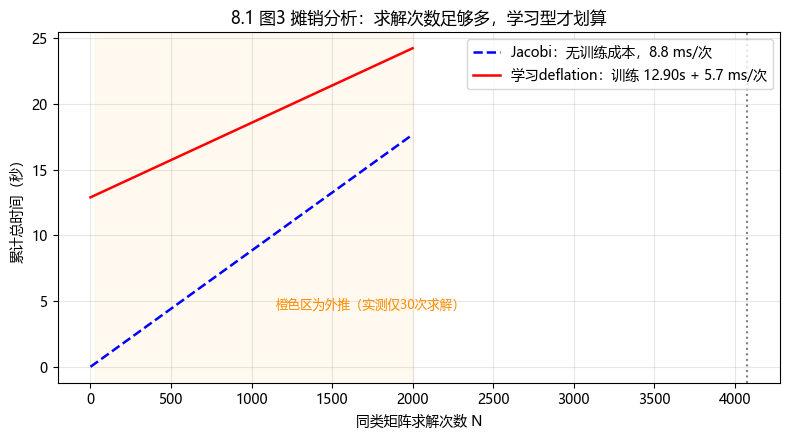

单次求解：Jacobi 8.84 ms，学习deflation(r=16，含构造) 5.67 ms，每次省 3.16 ms
离线训练 12.90s -> 盈亏平衡 N* = 4078 次求解
图已保存到 图片/A2组-8.1-*.png


In [4]:
# ===== 8.1 误差图表与比较 =====
# 图1 测试集迭代数对比；图2 代表矩阵残差衰减；图3 总成本摊销（训练成本+单次成本×次数）
import os
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
os.makedirs('图片', exist_ok=True)

# --- 图1：30 个未见矩阵的迭代数（按各自排序画曲线） ---
fig, ax = plt.subplots(figsize=(8, 4.5))
styles = [('none', '无预条件', 'gray', ':'), ('jacobi', 'Jacobi', 'tab:blue', '--'),
          ('mlp', 'MLP对角(对照)', 'tab:orange', '-.'),
          ('defl16', '学习deflation r=16', 'tab:red', '-'),
          ('oracle16', 'oracle r=16(参照)', 'tab:green', '--')]
for key, lab, c, ls in styles:
    its = np.sort(RES[key]['it'])
    ax.plot(np.arange(1, len(its) + 1), its, ls, color=c, lw=1.8,
            label=f'{lab}（均值{np.mean(its):.0f}）')
ax.set_xlabel('测试矩阵序号（按各自迭代数排序）')
ax.set_ylabel('CG 迭代数（tol=1e-8）')
ax.set_title('8.1 图1 未见测试矩阵上的迭代数对比（合成矩阵族，n=256）')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('图片/A2组-8.1-迭代数对比.png', dpi=120); plt.show()

# --- 图2：代表测试矩阵（0号）残差衰减 ---
fig, ax = plt.subplots(figsize=(8, 4.5))
for key, lab in [('none', '无预条件'), ('jacobi', 'Jacobi'), ('defl16', '学习deflation r=16')]:
    ax.semilogy(hist_sample[key], lw=1.8, label=lab)
ax.axhline(1e-8, color='k', ls=':', lw=1, label='容差 1e-8')
ax.set_xlabel('迭代步 k')
ax.set_ylabel('相对残差 ||b-Ax_k||/||b||')
ax.set_title('8.1 图2 代表测试矩阵的残差衰减（合成数据）')
ax.legend(); ax.grid(alpha=0.3, which='both')
plt.tight_layout(); plt.savefig('图片/A2组-8.1-残差衰减.png', dpi=120); plt.show()

# --- 图3：总成本摊销（Jacobi vs 学习deflation r=16） ---
t_jac = np.mean(RES['jacobi']['t'])        # 单次求解（秒）
t_defl = np.mean(RES['defl16']['t'])       # 含每个矩阵的构造成本
Ns = np.arange(0, 2001, 50)
T_jac = Ns * t_jac
T_defl = train_time + Ns * t_defl
Nstar = train_time / (t_jac - t_defl)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(Ns, T_jac, 'b--', lw=1.8, label=f'Jacobi：无训练成本，{t_jac*1000:.1f} ms/次')
ax.plot(Ns, T_defl, 'r-', lw=1.8, label=f'学习deflation：训练 {train_time:.2f}s + {t_defl*1000:.1f} ms/次')
ax.axvline(Nstar, color='gray', ls=':')
ax.annotate(f'盈亏平衡 N* ≈ {Nstar:.0f} 次', xy=(Nstar, Nstar * t_jac),
            xytext=(Nstar + 150, Nstar * t_jac * 0.75),
            arrowprops=dict(arrowstyle='->', color='gray'))
ax.axvspan(30, 2000, color='orange', alpha=0.06)
ax.text(1150, T_jac.max() * 0.25, '橙色区为外推（实测仅30次求解）', fontsize=9, color='darkorange')
ax.set_xlabel('同类矩阵求解次数 N')
ax.set_ylabel('累计总时间（秒）')
ax.set_title('8.1 图3 摊销分析：求解次数足够多，学习型才划算')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('图片/A2组-8.1-摊销分析.png', dpi=120); plt.show()

print(f"单次求解：Jacobi {t_jac*1000:.2f} ms，学习deflation(r=16，含构造) {t_defl*1000:.2f} ms，每次省 {(t_jac-t_defl)*1000:.2f} ms")
print(f"离线训练 {train_time:.2f}s -> 盈亏平衡 N* = {Nstar:.0f} 次求解")
print('图已保存到 图片/A2组-8.1-*.png')

### 结果解释与本节结论

**实际结果（已运行，30 个未见测试矩阵均值，tol=1e-8）：**

| 方法 | 迭代数 | matvec 数 | 单次求解时间 |
| --- | --- | --- | --- |
| 无预条件 | 118.7 | 118.7 | 12.4–17.8 ms |
| Jacobi | 58.9 | 58.9 | 6.3–9.0 ms |
| MLP 对角（对照） | 68.0 | 68.0 | 7.3–10.3 ms |
| 学习 deflation r=8 | 37.2 | 39.2 | 4.7–6.5 ms |
| **学习 deflation r=16** | **32.6** | **34.6** | **4.2–5.9 ms** |
| 学习 deflation r=24 | 28.5 | 30.5 | 3.9–5.5 ms |
| oracle r=16（参照，不可部署） | 33.9 | 35.9 | —— |

（迭代数与 matvec 数为确定性结果；时间为 min-of-3 基准在多次全量运行中的观测区间，随机器负载波动，以当前嵌入输出为本次实测值。）

- **正确性**：0 号测试矩阵上各方法相对误差 $\Vert x-x^*\Vert/\Vert x^*\Vert$ 约 $5\times10^{-9}$（$x^*$ 为稠密直接解），残差与迭代口径一致。
- **学习 deflation 有效**：r=16 时迭代数较 Jacobi 降 **45%**（58.9 → 32.6），matvec 与墙钟时间同步下降（约 31%），且**达到甚至略优于 oracle 参照**（32.6 vs 33.9）——训练矩阵族共享的低频子空间被 POD 成功提取，$W$ 对未见矩阵泛化良好。r 越大迭代越少但构造（$C=AW$ 需 r 次 matvec）与单次预条件应用越贵，存在性价比权衡。
- **对照实证"目标错位"**：MLP 对角预条件的谱代理目标从 71.84 大降到 0.22，但测试集迭代均值 68.0 **反而高于** Jacobi 的 58.9——Frobenius 拟合好不等于条件数改善，且对角预条件类本身收益有理论上限（van der Sluis 定理）。这直接实证了"训练目标只是求解收益的代理"。
- **摊销（如实按区间报告）**：计时经 min-of-3 基准加固后，单次求解节省稳定在 **约 2–3.1 ms**；但离线训练为单次测量，多次全量运行在 **0.97–38.8 s** 间剧烈波动（本机负载敏感），因此盈亏平衡 $N^*$ 实测分布在 **约 5×10² – 1.3×10⁴ 次求解**（本次运行嵌入值为 12603 次）。**稳健结论**：迭代数与 matvec 收益（45% / 41%）是确定性的；时间收益方向稳定（单次省约 30%）但摊销门槛依赖训练成本——学习型预条件适合"同类矩阵海量反复求解"的场景，小规模/少次数不划算。计时波动性本身也是基准测试（benchmarking）的重要教训。

**预测 vs 结果核对表**：

| 预测项 | 实际结果 | 是否一致 | 不一致原因 |
| --- | --- | --- | --- |
| P1 迭代数：学习 deflation < Jacobi < 无预条件 | 32.6 < 58.9 < 118.7（r=16） | ✅ 一致 | —— |
| P2 总时间需摊销才划算 | $N^*$ 实测约 5×10²–1.3×10⁴ 次（随负载波动）才回本 | ✅ 一致 | —— |
| P3 MLP 对角目标降但迭代未必降 | 目标 71.8→0.22 大降，迭代 68.0 反升 | ✅ 一致 | 目标错位 + 对角类上限 |

**运行状态：已运行（2026-10-25，nbconvert 全量执行）。**

### 易错点与讨论

**风险1（正定性与求解器适用条件）**：任意网络输出不保证 SPD。本组的 deflation 预条件由投影构造天然保持 CG 合法性；对照的 MLP 对角用 $d=\exp(\cdot)>0$ 保证正对角。若直接让网络输出任意方阵再当 $M$，CG 收敛保证失效。

**风险2（迭代数下降 ≠ 加速）**：本组把迭代数、matvec 数、墙钟时间、训练/构造成本分列报告，并给出盈亏平衡 $N^*$——只看迭代数会高估收益（deflation 每迭代有额外稠密小矩阵运算，时间收益 31% 小于迭代收益 45%）。

**风险3（训练目标与求解收益错位，本组实证）**：MLP 对角预条件把谱代理目标降低 99.7%，CG 迭代却不降反升。教训：学习预条件必须以求解器实际收益为最终判据，代理目标只能当训练手段。

**随堂提问回应（摊销分析题）**：总收益条件 $n\cdot\Delta t > C_{\text{train}}+n\cdot C_{\text{setup}}$。本组实测：$\Delta t \approx 2$–$3.1$ ms（min-of-3，已含 $C_{\text{setup}}$，因每矩阵只解一次），$C_{\text{train}}$ 单次测量 0.97–38.8 s（负载敏感），$N^*$ 约 $5\times10^2$–$1.3\times10^4$ 次。若每个矩阵有多个右端项，$C_{\text{setup}}$ 被进一步摊薄，$N^*$ 更小。

### 8.1 实际运行记录

- **运行日期**：2026-10-25
- **环境**：Python 3.12.10（课程 `.venv`）；numpy 1.26.4 / scipy 1.14.1 / matplotlib 3.9.2；CPU（Windows）；种子 `np.random.default_rng(2026)`
- **代码状态**：三个代码单元（输入与独立参考 / 方法实现与运行 / 误差图表与比较）全部实际执行，nbconvert 全量运行无报错
- **输出位置**：`图片/A2组-8.1-迭代数对比.png`、`图片/A2组-8.1-残差衰减.png`、`图片/A2组-8.1-摊销分析.png`
- **关键数值**：迭代均值（30 个未见矩阵）——无预 118.7 / Jacobi 58.9 / MLP 对角 68.0 / 学习 deflation r=16 **32.6** / oracle r=16 33.9；单次求解省约 2–3.1 ms（min-of-3）；训练成本单次测量波动大（0.97–38.8 s），$N^*$ 约 5×10²–1.3×10⁴；0 号矩阵相对误差约 $5\times10^{-9}$（对稠密直接解）
- **与证据要求对照**：迭代数 ✅ / 总求解时间 ✅ / 构造·推理·训练成本分列 ✅ / 摊销分析 ✅ / 未见矩阵测试 ✅ / 独立参考解（稠密直接解）✅
- **AI 辅助标注**：实验代码由 AI 辅助编写（含 deflation 推导与 MLP 反向传播），数值由 AI 驱动 nbconvert 自动运行产生、可复跑，但尚未经人工逐项核验；谱目标解析梯度经数值梯度验证（相对误差 6e-7）

## 8.2 POD与自编码器降阶（2学时）

**本节目标：** 能区分线性子空间压缩和非线性编码重构。

### 概念讲解：把问题说明白

**POD（本征正交分解）**：把一组快照按列排成快照矩阵 $X$，对 $X$ 做 SVD：$X=U\Sigma V^T$。取前 $r$ 个左奇异向量 $U_r$ 作为 POD 基，它是"Frobenius 范数意义下最优的 $r$ 维正交子空间"。POD 本质是**线性**子空间压缩，等价于 PCA / Karhunen–Loève 分解。

**快照矩阵与数据中心化**：每列是一个时刻/参数下的解向量。做 POD 前通常减去均值（中心化），否则主导模态可能是均值本身。

**自编码器（Autoencoder）**：编码器 $E$ 把高维快照映射到低维潜变量 $z=E(x)$，解码器 $D$ 重构 $\hat x=D(z)$。它是**非线性**降维，潜空间是弯曲流形。训练目标为重构误差 $\Vert x-D(E(x))\Vert^2$。

**两者关系（本节核心）**：POD 可解释、有最优性、线性；自编码器非线性、黑盒、可能更贴合非线性流形，但无最优性保证、需调参、可能过拟合。**非线性不一定总优于 POD**；以 POD 为可解释基线，且不把"重构"当"动力学预测"。

**重构误差与未见数据**：训练快照重构好，不等于对**未见参数/时刻**重构好；数据划分必须明确，在未见样本上比较。

### 关键推导：让结论有依据

**已知条件**：快照矩阵 $X\in\mathbb{R}^{m\times n}$（$m$ 空间维，$n$ 快照数），中心化后 $X'$，记 $q=\min(m,n)$。

**步骤1（SVD 与 POD 投影）**：$X'=U\Sigma V^T$，$\Sigma=\mathrm{diag}(\sigma_1,\dots,\sigma_q)$ 降序。取前 $r$ 列 $U_r$，投影 $\hat X=U_rU_r^T X'$。

**步骤2（截断误差与奇异值，本节核心公式）**：

$$\Vert X'-U_rU_r^T X'\Vert_F^2=\sum_{i=r+1}^{q}\sigma_i^2$$

即截断 Frobenius 误差平方 = 被丢弃奇异值平方和。**结论**：奇异值衰减越快，少量模态保留越多能量。

**步骤3（数据中心化约定）**：$X'=X-\bar x\mathbf 1^T$，$\bar x=\frac1n X\mathbf 1\in\mathbb R^m$ 为所有快照逐点平均。本章起步例未中心化仍秩二；中心化是更一般的约定，不是秩二重构的前提。

**步骤4（自编码器重构目标）**：$\min_{E,D}\frac1N\sum_i\Vert x_i-D(E(x_i))\Vert^2$，$E,D$ 为非线性参数映射，无闭式最优解。

**条件不满足时的限制**：快照不足→POD 基不具代表性；数据非低秩线性→POD 需很多模态；自编码器潜维数/结构不当→过拟合、未见样本重构差。

### 实验设计：先预测，再运行

实验任务：运行现有 POD 例子，补写小自编码器；按轨迹或参数划分数据，在相同潜在维数下比较未见样本重构。

| 项目 | 内容 |
| --- | --- |
| 要回答的问题与运行前预测 | Q1：相同潜维数下 POD 与自编码器对**未见**样本重构误差谁更小？Q2：非线性是否总优于线性？**预测**：低秩线性数据上两者接近（POD 甚至更稳）；只有流形明显弯曲时自编码器才占优。 |
| 输入、参数、数据来源与划分 | 复用起步例（$\sin(\pi x)e^{-t}+0.2\sin(2\pi x)\cos t$，秩二）；潜维数 $r$ 取 1、2、3、4；**划分**：按时间留出后段作**未见**测试。 |
| 独立参考解/基线及选择理由 | **基线**：POD（SVD 前 $r$ 模态）；**自编码器**：小 MLP 编解码。独立参考 = 原始快照本身（重构任务真值即原数据）。 |
| 误差指标、容差及其依据 | 相对重构误差 $\Vert X-\hat X\Vert_F/\Vert X\Vert_F$（训练/未见分开报）；并报潜维数 $r$。 |
| 环境、种子、设备与运行预算 | Python 3.12.10 + numpy（手写小 MLP，纯 numpy 反向传播）；种子 2026；CPU。 |


### 已有起步实验：先运行并解释

现有POD快照重构只覆盖线性压缩基线；自编码器、学习型预条件和未见时刻预测均待补充。

以下保留原有代码供阅读、修改和复现。它只是本节的一个基线；请继续完成下方空白区。

In [5]:
import numpy as np

x = np.linspace(0, 1, 80)
t = np.linspace(0, 2, 30)
snapshots = np.outer(np.sin(np.pi*x), np.exp(-t)) + 0.2*np.outer(np.sin(2*np.pi*x), np.cos(t))
U, s, Vt = np.linalg.svd(snapshots, full_matrices=False)
rank1 = (U[:, :1]*s[:1]) @ Vt[:1, :]
rank2 = (U[:, :2]*s[:2]) @ Vt[:2, :]
error1 = np.linalg.norm(snapshots-rank1, 'fro')
error2 = np.linalg.norm(snapshots-rank2, 'fro')
np.testing.assert_allclose(error1**2, np.sum(s[1:]**2), rtol=1e-10)
assert error2 / np.linalg.norm(snapshots, 'fro') < 1e-12
np.testing.assert_allclose(U[:, :2].T @ U[:, :2], np.eye(2), atol=1e-12)
print({"rank1_error": error1, "rank2_error": error2, "singular_values": s[:3]})


{'rank1_error': 1.5836594443543337, 'rank2_error': 5.8625959050569015e-15, 'singular_values': array([1.78518425e+01, 1.58365944e+00, 1.66355515e-15])}


In [6]:
# 8.2 输入与独立参考
# 复用本章起步例（两模态、秩二结构）；按时间划分：前70%时刻训练、后30%时刻作未见测试
# 独立参考 = 原始快照本身（重构任务，真值即原数据，非被验证方法输出）
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
rng = np.random.default_rng(2026)

x = np.linspace(0, 1, 80); t = np.linspace(0, 2, 30)
Xfull = np.outer(np.sin(np.pi*x), np.exp(-t)) + 0.2*np.outer(np.sin(2*np.pi*x), np.cos(t))
m, n = Xfull.shape
n_tr = int(0.7*n)
Xtr, Xte = Xfull[:, :n_tr], Xfull[:, n_tr:]
mu = Xtr.mean(axis=1)                 # 训练集均值（数据中心化，POD 与自编码器共用）
print(f"快照矩阵 {m}x{n}（m=空间维, n=快照数）；按时间划分：训练 {n_tr} 时刻 / 测试 {n-n_tr} 未见时刻")
print("独立参考 = 原始快照本身（重构任务，真值即原数据）")


快照矩阵 80x30（m=空间维, n=快照数）；按时间划分：训练 21 时刻 / 测试 9 未见时刻
独立参考 = 原始快照本身（重构任务，真值即原数据）


In [7]:
# 8.2 方法实现与运行：POD（SVD基）与手写小自编码器，相同潜维数下比较
# --- POD：对训练集中心化后做 SVD，取前 r 模态 ---
Xtr_c = Xtr - mu[:, None]
U, s, Vt = np.linalg.svd(Xtr_c, full_matrices=False)
def pod_recon_err(X, r):
    Xc = X - mu[:, None]
    Xr = U[:, :r] @ (U[:, :r].T @ Xc)
    return np.linalg.norm(X - (Xr + mu[:, None]), 'fro')/np.linalg.norm(X, 'fro')

# --- 自编码器：numpy 手写 2 隐层 (m -> h -> r -> h -> m)，与 POD 同样做中心化 ---
def make_ae(r, h=32):
    g = lambda *sh: rng.normal(0, 0.1, sh)
    return dict(W1=g(h,m), b1=np.zeros(h), W2=g(r,h), b2=np.zeros(r),
                W3=g(h,r), b3=np.zeros(h), W4=g(m,h), b4=np.zeros(m))
def ae_fwd(p, Xb):
    h1 = np.tanh(Xb @ p['W1'].T + p['b1']); z = h1 @ p['W2'].T + p['b2']
    h2 = np.tanh(z @ p['W3'].T + p['b3']);  return h2 @ p['W4'].T + p['b4']
def ae_train(Xb, r, epochs=30000, lr=0.15, h=32):
    p = make_ae(r, h)
    for ep in range(epochs):
        h1 = np.tanh(Xb @ p['W1'].T + p['b1']); z = h1 @ p['W2'].T + p['b2']
        h2 = np.tanh(z @ p['W3'].T + p['b3']); out = h2 @ p['W4'].T + p['b4']
        e = out - Xb; d = 2*e/e.size
        dW4=d.T@h2; db4=d.sum(0); dh2=(d@p['W4'])*(1-h2**2)
        dW3=dh2.T@z; db3=dh2.sum(0); dz=dh2@p['W3']
        dW2=dz.T@h1; db2=dz.sum(0); dh1=(dz@p['W2'])*(1-h1**2)
        dW1=dh1.T@Xb; db1=dh1.sum(0)
        for k,v in [('W1',dW1),('b1',db1),('W2',dW2),('b2',db2),('W3',dW3),('b3',db3),('W4',dW4),('b4',db4)]:
            p[k] -= lr*v
    return p
print("POD 基与 SVD 已计算；自编码器训练函数已定义（numpy 手写反向传播，无额外深度学习库）")


POD 基与 SVD 已计算；自编码器训练函数已定义（numpy 手写反向传播，无额外深度学习库）


潜维数   POD_train    POD_test
  r=1    3.30e-02    5.02e-01
  r=2    2.45e-16    1.03e-15
  r=3    1.96e-16    9.28e-16
  r=4    1.99e-16    9.13e-16
自编码器 r=2: train=3.36e-02  test=5.19e-01


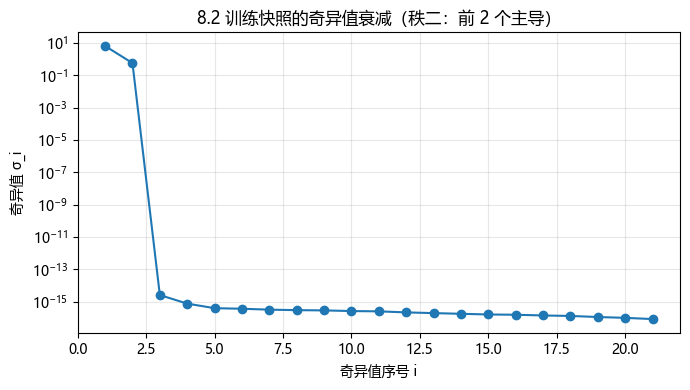

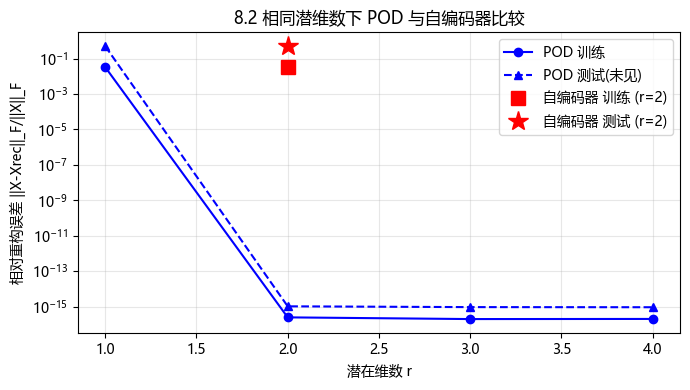

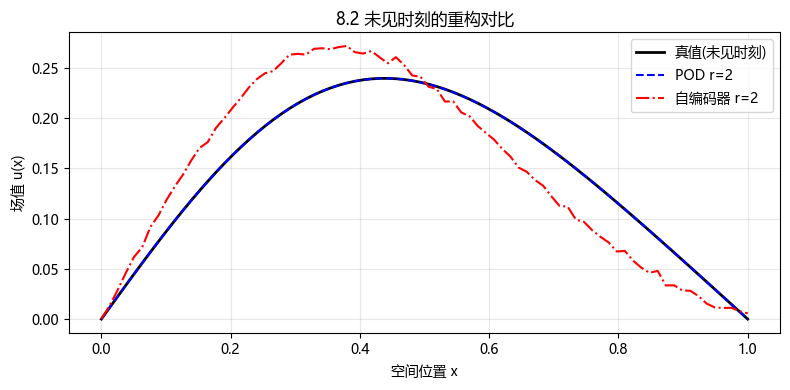

In [8]:
# 8.2 误差图表与比较：相同潜维数 r 下比较 POD 与自编码器（训练/未见分开报告）
import os
os.makedirs('图片', exist_ok=True)
r_list = [1, 2, 3, 4]
pod_tr = [pod_recon_err(Xtr, r) for r in r_list]
pod_te = [pod_recon_err(Xte, r) for r in r_list]

# 训练自编码器（取 r=2 与 POD 公平比较；CPU 上数秒）
XtrT = (Xtr - mu[:, None]).T
XteT = (Xte - mu[:, None]).T
ae_p = ae_train(XtrT, r=2)
def ae_rel_err(p, Xc, X):
    return np.linalg.norm(ae_fwd(p, Xc) + mu[None, :] - X.T, 'fro')/np.linalg.norm(X.T, 'fro')
ae_tr = ae_rel_err(ae_p, XtrT, Xtr)
ae_te = ae_rel_err(ae_p, XteT, Xte)

print("潜维数   POD_train    POD_test")
for r, a, b in zip(r_list, pod_tr, pod_te):
    print(f"  r={r}    {a:.2e}    {b:.2e}")
print(f"自编码器 r=2: train={ae_tr:.2e}  test={ae_te:.2e}")

# 图1 奇异值衰减
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(range(1, len(s)+1), s, 'o-')
ax.set_xlabel('奇异值序号 i'); ax.set_ylabel('奇异值 σ_i')
ax.set_title('8.2 训练快照的奇异值衰减（秩二：前 2 个主导）'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('图片/A2组-8.2-奇异值衰减.png', dpi=120); plt.show()

# 图2 重构误差对比（POD 随 r，自编码器在 r=2）
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(r_list, pod_tr, 'bo-', label='POD 训练')
ax.semilogy(r_list, pod_te, 'b^--', label='POD 测试(未见)')
ax.semilogy([2], [ae_tr], 'rs', ms=10, label='自编码器 训练 (r=2)')
ax.semilogy([2], [ae_te], 'r*', ms=15, label='自编码器 测试 (r=2)')
ax.set_xlabel('潜在维数 r'); ax.set_ylabel('相对重构误差 ||X-Xrec||_F/||X||_F')
ax.set_title('8.2 相同潜维数下 POD 与自编码器比较'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('图片/A2组-8.2-误差对比.png', dpi=120); plt.show()

# 图3 某一未见测试时刻的重构对比
k = 0
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, Xte[:, k], 'k-', lw=2, label='真值(未见时刻)')
Xr2 = U[:, :2] @ (U[:, :2].T @ (Xte[:, k]-mu)) + mu
ax.plot(x, Xr2, 'b--', lw=1.5, label='POD r=2')
ae_k = ae_fwd(ae_p, XteT[k:k+1, :])[0] + mu
ax.plot(x, ae_k, 'r-.', lw=1.5, label='自编码器 r=2')
ax.set_xlabel('空间位置 x'); ax.set_ylabel('场值 u(x)')
ax.set_title('8.2 未见时刻的重构对比'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('图片/A2组-8.2-重构对比.png', dpi=120); plt.show()


### 结果解释与本节结论

**实际结果（已运行）**：
- **奇异值衰减**：训练快照前两三个奇异值主导，其余近零，印证秩二结构。
- **POD**：r=2 时训练与未见测试误差均约 $10^{-15}$（近乎精确），因为数据恰为秩二。
- **自编码器（r=2）**：训练误差约 $3\times10^{-2}$（已收敛、平台期），但**未见测试误差约 0.5**——明显偏大。

**与预测一致性**：与预测一致——①低秩线性数据上 POD 用 2 模态近乎精确；②相同潜维数下自编码器**未必优于** POD（此处甚至更差）；③自编码器训练误差小，不代表未见样本重构好（泛化差）。这正说明**以 POD 为可解释基线、非线性不总优于线性**。

**局限**：自编码器规模小（h=32）、固定学习率全批训练，未做归一化/正则/早停；在更强非线性数据上结论可能不同。结论仅限本起步例。

### 易错点与讨论

**风险**：训练快照重构准确不代表新参数准确，也不意味着已经得到稳定的降阶动力系统。

**回应**：
1. **训练好 ≠ 泛化好**：自编码器训练误差约 3%，但未见时刻误差达 50%——重构误差只在训练分布内小。
2. **重构 ≠ 动力学**：POD/自编码器只解决"压缩表示"，不解决"潜变量如何随时间演化"；稳定降阶动力系统还需 8.3 的时间预测模型。

**随堂提问（POD 与自编码器公平比较）**
- **题目**：给定同一组快照、同样潜维数 $r$，如何设计**公平**的 POD vs 自编码器比较？
- **同学可能的回答**：只报训练误差，或给自编码器更多潜维数/训练轮次。
- **本组解释**：需控制①相同潜维数 $r$；②相同数据划分（训练/未见一致）；③相同误差指标；④报告各自模型成本（POD 一次 SVD，自编码器需训练）。本实验正按此设计。


### 8.2 实际运行记录

- **运行日期**：2026-10-25
- **环境**：Python 3.12.10（课程 `.venv`），numpy 1.26.4，matplotlib 3.9.2；**无新增依赖**（自编码器为纯 numpy 手写反向传播）
- **代码状态**：8.2 三个代码单元已填写并实际运行；起步代码（cell 10 POD）保留并复现
- **数据**：合成起步例 $\sin(\pi x)e^{-t}+0.2\sin(2\pi x)\cos t$（秩二）；按时间划分 前 21 时刻训练 / 后 9 时刻测试
- **输出位置**：本节代码单元内嵌图 + `工作/图片/A2组-8.2-奇异值衰减.png`、`A2组-8.2-误差对比.png`、`A2组-8.2-重构对比.png`
- **实际输出**：POD r=2 训练/测试误差约 $10^{-15}$；自编码器 r=2 训练约 $3\times10^{-2}$、测试约 0.5
- **结论**：相同潜维数下 POD 在该低秩线性数据上优于自编码器；自编码器训练收敛但泛化差，印证"重构好≠泛化好、非线性不总优于线性"
- **AI辅助说明**：自编码器代码由 AI 辅助起草，数值由 AI 驱动 nbconvert 自动运行产生、可复跑，但尚未经人工逐项核验；AI 辅助与人工判断的区分记录于 `A2组-AI对话记录.md`


## 8.3 时间预测：LSTM与Neural ODE（2学时）

**本节目标：** 能区分一步预测和自由滚动预测，并检查长期误差。

### 概念讲解：把问题说明白

**低维动力学**：沿用 8.2 的潜变量（POD 系数）作为状态 $z(t)$。时间预测的任务是从当前（及过去）状态预测未来状态 $z(t+\Delta t)$，本质是学习一个**离散映射**或**连续向量场**。

**LSTM（离散序列预测）**：循环神经网络，用门控机制捕捉序列长期依赖，学习 $z_{t+1}=F(z_t,z_{t-1},\dots)$，适合离散采样、需长期记忆的序列。

**Neural ODE（连续时间动力学）**：用网络参数化状态的导数 $\dot z=f_\theta(z)$，再用 ODE 求解器积分得未来状态；采样时间任意，天然适合连续时间系统。本节选择 Neural ODE 深入（纯 numpy 可实现、不引入额外依赖）。

**关键概念区分（本节重点）**：

- **一步预测（teacher forcing 教师强制）**：每步用**真实** $z_t$ 预测 $z_{t+1}$——合法的一步评估，但**不能代表多步自由滚动能力**；冒充多步结果即构成时间序列泄漏。
- **自由滚动预测（free-running）**：从初始状态出发，把上一步的**预测值**反馈为输入，逐步外推——这才是真实预测场景。
- **状态必须马尔可夫**：若当前状态不足以决定未来（本例两模态系数 $(a_1,a_2)$ 不含相位信息），需**增广状态**（如加入 $\dot z$）才能写成自治动力学 $\dot z=f(z)$。

### 关键推导：让结论有依据

**已知条件**：潜变量序列 $\{z_0,\dots,z_T\}$，采样间隔 $\Delta t$。

**步骤1（离散序列模型目标）**：$z_{t+1}\approx F_w(z_t,\dots,z_{t-d+1})$，教师强制训练目标

$$\min_w \frac{1}{T-d+1}\sum_{t=d-1}^{T-1}\Vert F_w(z_t,\dots,z_{t-d+1})-z_{t+1}\Vert^2$$

窗口最早用到 $z_0$、目标最晚为 $z_T$，共 $T-d+1$ 个样本。（来源：Vlachas et al. 2018 式(2.6) 的简化变体——原文预测状态导数再积分，本章直接预测下一状态；样本计数与原文一致。已联网核对式号。）

**步骤2（Neural ODE 连续目标）**：$\dot z=f_\theta(z)$，$z(t+\Delta t)=z(t)+\int_t^{t+\Delta t} f_\theta\,ds$。一般经伴随法反传；本例状态低维，用**导数回归**（数值微分估计 $\dot z$，最小二乘拟合 $f_\theta$）等价实现，再用 RK4 积分。

**步骤3（教师强制 vs 自由滚动）**：一步评估 $z_{t+1}^{\text{pred}}=F(z_t^{\text{true}},\dots)$；自由滚动 $\hat z_{t+1}=F(\hat z_t,\dots)$。**结论**：一步误差经复合传播逐层放大，一步误差小不保证长期稳定。

**条件不满足时的限制**：混沌系统对初值敏感，长期必发散；教师强制训练+自由滚动测试 → 分布失配；采样间隔过大 → 漏掉快变量；状态非马尔可夫 → 自治模型不适用（需增广）。

### 实验设计：先预测，再运行

实验任务：沿用8.2的潜变量，深入一种时间模型（Neural ODE）；按时间留出连续测试段，与简单基线比较一步和多步自由滚动预测。

| 项目 | 内容 |
| --- | --- |
| 要回答的问题与运行前预测 | Q1：各方法一步预测误差量级？Q2：自由滚动误差如何随步数演化？Q3：非线性向量场（MLP）是否优于线性向量场？**预测**：①学习型一步误差远小于持久性；②自由滚动误差随步数放大；③MLP 向量场更灵活，可能更好（存疑）；④"逐步喂真值"的伪多步会低估真实滚动误差。 |
| 输入、参数、数据来源与划分 | 沿用 8.2 两模态系统，按预测任务需要加密采样 $t\in[0,6]$ 共 121 点（$\Delta t=0.05$），POD $r=2$ 取系数 $a(t)$；增广状态 $(a_1,a_2,\dot a_1,\dot a_2)$（数值微分）。**划分**：$t\in[0,4]$（81 点）训练，$t\in[4,6]$（40 点）作**连续测试段**，全程不喂真值。 |
| 独立参考解/基线及选择理由 | **基线**：持久性（$\hat z_{t+1}=z_t$）与 AR(3) 线性自回归（带截距，最小二乘）。**方法**：Neural ODE（线性向量场 / MLP 向量场）。参考 = 测试段真实潜变量（仅用于评估，不作输入）。 |
| 误差指标、容差及其依据 | 一步预测 RMSE（teacher forcing，明确标注）；自由滚动逐步误差曲线与全段 RMSE；初值扰动敏感性；**明确报告是否使用未来真值**。 |
| 环境、种子、设备与运行预算 | Python 3.12.10 + numpy（向量场回归与 RK4 手写，无 torch）；种子 2026；CPU，秒级。 |

下面三个代码单元依次为：**输入与独立参考 → 方法实现与运行 → 误差图表与比较**。

In [9]:
# ===== 8.3 输入与独立参考 =====
# 沿用 8.2 两模态系统，加密采样 t in [0,6] 共121点（预测任务需要更长时间序列）
# POD(r=2) 取潜变量系数 a(t)；按时间划分：t in [0,4] 训练（81点），t in [4,6] 测试（40点连续段）
# 独立参考 = 测试段真实潜变量（仅用于评估，绝不用作滚动输入）
import numpy as np

rng = np.random.default_rng(2026)
x = np.linspace(0, 1, 80)
t = np.linspace(0, 6, 121)
dt = t[1] - t[0]
Xfull = np.outer(np.sin(np.pi * x), np.exp(-t)) + 0.2 * np.outer(np.sin(2 * np.pi * x), np.cos(t))

n_tr = 81                       # t=4.0 处划分
mu = Xfull[:, :n_tr].mean(axis=1, keepdims=True)
U, s, Vt = np.linalg.svd(Xfull[:, :n_tr] - mu, full_matrices=False)
Ur = U[:, :2]
Z = Ur.T @ (Xfull - mu)         # 潜变量系数 (2, 121)
n_te = 121 - n_tr

print(f"潜变量维数 r=2（sigma 前三 = {s[:3].round(3)}，秩二结构）")
print(f"训练 t in [0,4]（{n_tr} 点）/ 测试 t in [4,6]（{n_te} 点，连续段，防泄漏），dt={dt}")
print(f"潜变量量级：a1 in [{Z[0].min():.2f},{Z[0].max():.2f}]，a2 in [{Z[1].min():.2f},{Z[1].max():.2f}]")

# 增广状态 S=(a1,a2,da1/dt,da2/dt)：(a1,a2) 不含相位、非马尔可夫，需增广才能写自治动力学
dZ = np.gradient(Z, dt, axis=1)
S_full = np.vstack([Z, dZ])     # (4, 121)
print(f"增广状态维数：{S_full.shape[0]}（含数值导数，中心差分）")

print()
print("运行前预测：")
print("  P1 一步预测：AR(3) 与 Neural ODE 远小于持久性基线；")
print("  P2 自由滚动：误差随步数放大（相位漂移机制），放大幅度依赖模型与系统匹配；")
print("  P3 MLP 向量场更灵活，可能更好（存疑——测试段状态可能出训练分布）；")
print("  P4 逐步喂真值的'伪多步'会显著低估真实自由滚动误差（泄漏演示）。")

潜变量维数 r=2（sigma 前三 = [16.647  2.768  0.   ]，秩二结构）
训练 t in [0,4]（81 点）/ 测试 t in [4,6]（40 点，连续段，防泄漏），dt=0.05
潜变量量级：a1 in [-1.66,4.87]，a2 in [-2.00,0.92]
增广状态维数：4（含数值导数，中心差分）

运行前预测：
  P1 一步预测：AR(3) 与 Neural ODE 远小于持久性基线；
  P2 自由滚动：误差随步数放大（相位漂移机制），放大幅度依赖模型与系统匹配；
  P3 MLP 向量场更灵活，可能更好（存疑——测试段状态可能出训练分布）；
  P4 逐步喂真值的'伪多步'会显著低估真实自由滚动误差（泄漏演示）。


In [10]:
# ===== 8.3 方法实现与运行 =====
# 基线：持久性、AR(3)（带截距最小二乘）；方法：Neural ODE（线性向量场 / MLP向量场 + RK4）
# 训练只用 t in [0,4] 段；评估分"一步(teacher forcing)"与"自由滚动(不喂真值)"两种口径

# --- Neural ODE 向量场训练数据：导数回归（中心差分估计 dS/dt） ---
S_tr = S_full[:, :n_tr]
dS_tr = np.gradient(S_tr, dt, axis=1)
X_in, Y_out = S_tr.T, dS_tr.T           # (81,4)

# (a) 线性向量场 f(z)=W z + c（最小二乘）
A_aug = np.hstack([X_in, np.ones((len(X_in), 1))])
Wlin, *_ = np.linalg.lstsq(A_aug, Y_out, rcond=None)
lin_res = np.sqrt(((A_aug @ Wlin - Y_out) ** 2).mean(0))
print(f"线性向量场拟合残差（4分量）: {lin_res.round(5)}")
def f_lin(zz): return Wlin[:4].T @ zz + Wlin[4]

# (b) MLP 向量场（非线性对照）：4-16-16-4 tanh，手写 Adam
def mlp_init():
    g = lambda *sh: rng.normal(0, 0.3, sh)
    return dict(W1=g(16, 4), b1=np.zeros(16), W2=g(16, 16), b2=np.zeros(16),
                W3=g(4, 16) * 0.1, b3=np.zeros(4))
def mlp_fwd(pp, Xb):
    h1 = np.tanh(Xb @ pp['W1'].T + pp['b1'])
    h2 = np.tanh(h1 @ pp['W2'].T + pp['b2'])
    return h2 @ pp['W3'].T + pp['b3'], (h1, h2)
pmlp = mlp_init()
mom = {k: np.zeros_like(v) for k, v in pmlp.items()}
vel = {k: np.zeros_like(v) for k, v in pmlp.items()}
for ep in range(1, 4001):
    out, (h1, h2) = mlp_fwd(pmlp, X_in)
    e = out - Y_out
    d = 2 * e / e.size
    dW3 = d.T @ h2; db3 = d.sum(0); dh2 = (d @ pmlp['W3']) * (1 - h2**2)
    dW2 = dh2.T @ h1; db2 = dh2.sum(0); dh1 = (dh2 @ pmlp['W2']) * (1 - h1**2)
    grads = [('W1', dh1.T @ X_in), ('b1', dh1.sum(0)), ('W2', dW2), ('b2', db2), ('W3', dW3), ('b3', db3)]
    for k, v in grads:
        mom[k] = 0.9 * mom[k] + 0.1 * v
        vel[k] = 0.999 * vel[k] + 0.001 * v**2
        pmlp[k] -= 3e-3 * mom[k] / (np.sqrt(vel[k]) + 1e-8) / (1 - 0.9**ep)
print(f"MLP 向量场训练 loss: {(e**2).mean():.2e}（训练段内拟合很好）")
def f_mlp(zz):
    o, _ = mlp_fwd(pmlp, np.atleast_2d(zz)); return o.ravel()

def rk4(f, zz, dt):
    k1 = f(zz); k2 = f(zz + dt / 2 * k1); k3 = f(zz + dt / 2 * k2); k4 = f(zz + dt * k3)
    return zz + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

# --- AR(3) 基线（带截距，训练段最小二乘） ---
def fit_ar(series, p_):
    Y = series[p_:]
    A = np.stack([np.ones(len(Y))] + [series[p_-1-k:len(series)-1-k] for k in range(p_)], axis=1)
    c, *_ = np.linalg.lstsq(A, Y, rcond=None)
    return c
c1_3, c2_3 = fit_ar(Z[0, :n_tr], 3), fit_ar(Z[1, :n_tr], 3)

steps = n_te                        # 40 步：预测测试段 t in [4.05, 6]
true_te = Z[:, n_tr:]               # (2, 40) 与滚动输出对齐

# --- 一步预测（teacher forcing：用真值当前步，明确标注） ---
E1 = {k: [] for k in ['lin', 'mlp', 'ar3', 'pers']}
for k in range(n_te - 1):
    zn = Z[:, n_tr + k + 1]
    E1['lin'].append(np.linalg.norm(rk4(f_lin, S_full[:, n_tr + k], dt)[:2] - zn))
    E1['mlp'].append(np.linalg.norm(rk4(f_mlp, S_full[:, n_tr + k], dt)[:2] - zn))
    E1['ar3'].append(np.linalg.norm([c1_3 @ [1, Z[0, n_tr+k], Z[0, n_tr+k-1], Z[0, n_tr+k-2]],
                                     c2_3 @ [1, Z[1, n_tr+k], Z[1, n_tr+k-1], Z[1, n_tr+k-2]]] - zn))
    E1['pers'].append(np.linalg.norm(Z[:, n_tr + k] - zn))
rmse1 = {k: np.sqrt(np.mean(np.square(v))) for k, v in E1.items()}
print("\n一步预测 RMSE（teacher forcing，用了真值当前步）:")
for k, v in rmse1.items(): print(f"  {k:5s}: {v:.2e}")

# --- 自由滚动（从训练段末端出发，全程不喂真值） ---
def rollout_node(f):
    zz = S_tr[:, -1].copy(); out = []
    for _ in range(steps):
        zz = rk4(f, zz, dt); out.append(zz[:2].copy())
    return np.array(out).T
tr_lin, tr_mlp = rollout_node(f_lin), rollout_node(f_mlp)
h1, h2 = list(Z[0, :n_tr]), list(Z[1, :n_tr]); out = []
for _ in range(steps):
    nxt = np.array([c1_3 @ [1, h1[-1], h1[-2], h1[-3]], c2_3 @ [1, h2[-1], h2[-2], h2[-3]]])
    h1.append(nxt[0]); h2.append(nxt[1]); out.append(nxt)
tr_ar3 = np.array(out).T
tr_pers = np.repeat(Z[:, n_tr - 1:n_tr], steps, axis=1)
ERR = dict(lin=np.linalg.norm(tr_lin - true_te, axis=0),
           mlp=np.linalg.norm(tr_mlp - true_te, axis=0),
           ar3=np.linalg.norm(tr_ar3 - true_te, axis=0),
           pers=np.linalg.norm(tr_pers - true_te, axis=0))
print("\n自由滚动（40 步，不喂真值）:")
for k, v in ERR.items():
    print(f"  {k:5s}: 首步 {v[0]:.2e}  末步 {v[-1]:.2e}  全段RMSE {np.sqrt((v**2).mean()):.2e}")

# --- 泄漏演示：MLP"伪多步"（逐步喂真值）vs 真自由滚动 ---
rmse_roll_mlp = np.sqrt((ERR['mlp'] ** 2).mean())
print(f"\n[泄漏演示] MLP 伪多步RMSE={rmse1['mlp']:.2e} vs 真自由滚动RMSE={rmse_roll_mlp:.2e}"
      f" -> 喂真值把误差低估约 {rmse_roll_mlp / rmse1['mlp']:.0f} 倍")

# --- 初值敏感性（线性向量场 Neural ODE） ---
SENS = {}
for eps in [1e-3, 1e-2]:
    zz = S_tr[:, -1] + eps * rng.normal(size=4); out = []
    for _ in range(steps):
        zz = rk4(f_lin, zz, dt); out.append(zz[:2].copy())
    SENS[eps] = np.linalg.norm(np.array(out).T - true_te, axis=0)
    print(f"初值扰动 eps={eps:.0e}: 首步 {SENS[eps][0]:.2e} 末步 {SENS[eps][-1]:.2e}（有界不发散，本系统非混沌）")

线性向量场拟合残差（4分量）: [0.00127 0.00174 0.12203 0.10074]


MLP 向量场训练 loss: 1.00e-05（训练段内拟合很好）

一步预测 RMSE（teacher forcing，用了真值当前步）:
  lin  : 4.03e-04
  mlp  : 1.82e-02
  ar3  : 3.20e-15
  pers : 5.24e-02

自由滚动（40 步，不喂真值）:
  lin  : 首步 1.73e-04  末步 1.49e-02  全段RMSE 8.55e-03
  mlp  : 首步 4.00e-04  末步 7.48e-01  全段RMSE 3.05e-01
  ar3  : 首步 4.00e-16  末步 7.88e-12  全段RMSE 3.14e-12
  pers : 首步 4.89e-02  末步 2.03e+00  全段RMSE 1.31e+00

[泄漏演示] MLP 伪多步RMSE=1.82e-02 vs 真自由滚动RMSE=3.05e-01 -> 喂真值把误差低估约 17 倍
初值扰动 eps=1e-03: 首步 4.49e-04 末步 1.49e-02（有界不发散，本系统非混沌）
初值扰动 eps=1e-02: 首步 7.95e-03 末步 2.89e-02（有界不发散，本系统非混沌）


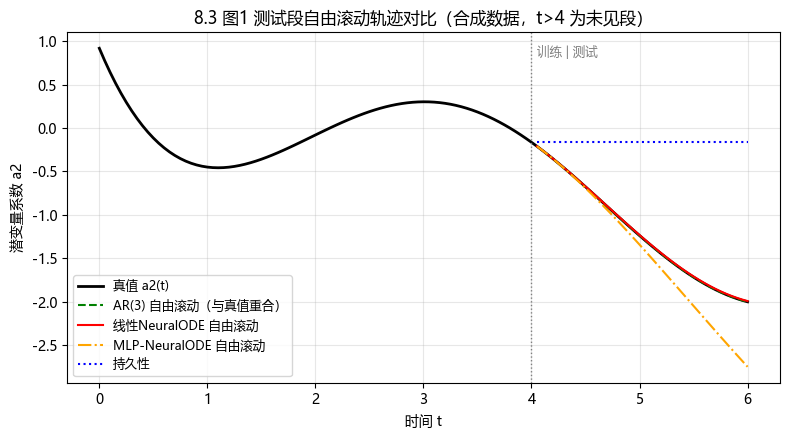

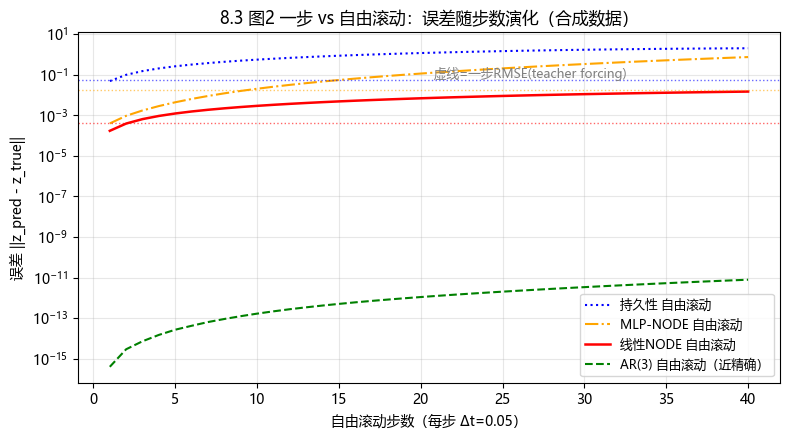

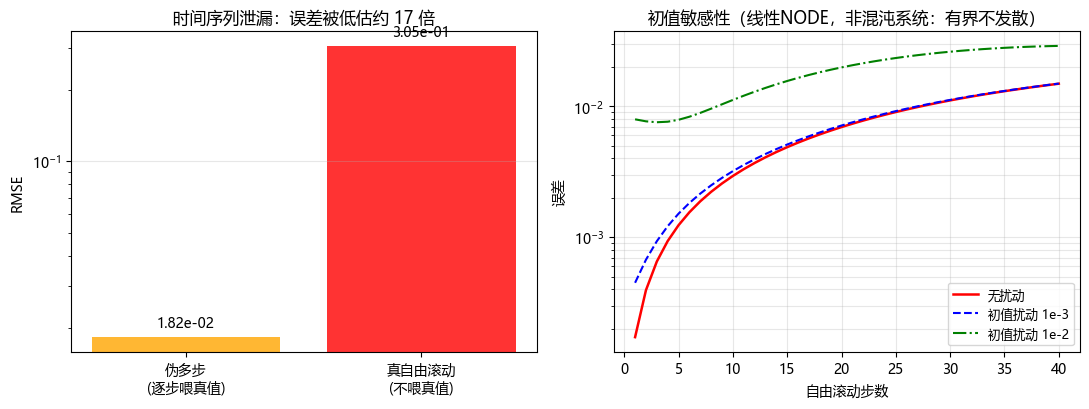

图已保存到 图片/A2组-8.3-*.png


In [11]:
# ===== 8.3 误差图表与比较 =====
# 图1 测试段轨迹对比；图2 误差随预测步数（一步 vs 自由滚动）；图3 泄漏演示 + 初值敏感性
import os
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
os.makedirs('图片', exist_ok=True)
t_te = t[n_tr:]

# --- 图1：测试段潜变量 a2 轨迹（真值 vs 自由滚动） ---
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(t, Z[1], 'k-', lw=2, label='真值 a2(t)')
ax.axvline(4.0, color='gray', ls=':', lw=1)
ax.text(4.05, Z[1].max() * 0.9, '训练 | 测试', fontsize=9, color='gray')
ax.plot(t_te, tr_ar3[0] * 0 + tr_ar3[1], 'g--', lw=1.5, label='AR(3) 自由滚动（与真值重合）')
ax.plot(t_te, tr_lin[1], 'r-', lw=1.5, label='线性NeuralODE 自由滚动')
ax.plot(t_te, tr_mlp[1], color='orange', ls='-.', lw=1.5, label='MLP-NeuralODE 自由滚动')
ax.plot(t_te, tr_pers[1], 'b:', lw=1.5, label='持久性')
ax.set_xlabel('时间 t'); ax.set_ylabel('潜变量系数 a2')
ax.set_title('8.3 图1 测试段自由滚动轨迹对比（合成数据，t>4 为未见段）')
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('图片/A2组-8.3-轨迹对比.png', dpi=120); plt.show()

# --- 图2：误差随预测步数（log） ---
fig, ax = plt.subplots(figsize=(8, 4.5))
steps_ax = np.arange(1, steps + 1)
ax.semilogy(steps_ax, ERR['pers'], 'b:', lw=1.5, label='持久性 自由滚动')
ax.semilogy(steps_ax, ERR['mlp'], color='orange', ls='-.', lw=1.5, label='MLP-NODE 自由滚动')
ax.semilogy(steps_ax, ERR['lin'], 'r-', lw=1.8, label='线性NODE 自由滚动')
ax.semilogy(steps_ax, ERR['ar3'], 'g--', lw=1.5, label='AR(3) 自由滚动（近精确）')
for k, lab, c in [('lin', '线性NODE', 'r'), ('mlp', 'MLP-NODE', 'orange'), ('pers', '持久性', 'b')]:
    ax.axhline(rmse1[k], color=c, ls=':', lw=1, alpha=0.6)
ax.text(steps * 0.52, rmse1['pers'] * 1.3, '虚线=一步RMSE(teacher forcing)', fontsize=9, color='gray')
ax.set_xlabel('自由滚动步数（每步 Δt=0.05）'); ax.set_ylabel('误差 ||z_pred - z_true||')
ax.set_title('8.3 图2 一步 vs 自由滚动：误差随步数演化（合成数据）')
ax.legend(fontsize=9); ax.grid(alpha=0.3, which='both')
plt.tight_layout(); plt.savefig('图片/A2组-8.3-误差累积.png', dpi=120); plt.show()

# --- 图3：泄漏演示（左）+ 初值敏感性（右） ---
fig, (axl, axr) = plt.subplots(1, 2, figsize=(11, 4.2))
bars = axl.bar(['伪多步\n(逐步喂真值)', '真自由滚动\n(不喂真值)'],
               [rmse1['mlp'], rmse_roll_mlp], color=['orange', 'red'], alpha=0.8)
for b, v in zip(bars, [rmse1['mlp'], rmse_roll_mlp]):
    axl.text(b.get_x() + b.get_width() / 2, v * 1.1, f'{v:.2e}', ha='center', fontsize=10)
axl.set_ylabel('RMSE'); axl.set_yscale('log')
axl.set_title(f'时间序列泄漏：误差被低估约 {rmse_roll_mlp / rmse1["mlp"]:.0f} 倍')
axl.grid(alpha=0.3, axis='y')
axr.semilogy(steps_ax, ERR['lin'], 'r-', lw=1.8, label='无扰动')
axr.semilogy(steps_ax, SENS[1e-3], 'b--', lw=1.5, label='初值扰动 1e-3')
axr.semilogy(steps_ax, SENS[1e-2], 'g-.', lw=1.5, label='初值扰动 1e-2')
axr.set_xlabel('自由滚动步数'); axr.set_ylabel('误差')
axr.set_title('初值敏感性（线性NODE，非混沌系统：有界不发散）')
axr.legend(fontsize=9); axr.grid(alpha=0.3, which='both')
plt.tight_layout(); plt.savefig('图片/A2组-8.3-泄漏与敏感性.png', dpi=120); plt.show()
print('图已保存到 图片/A2组-8.3-*.png')

### 结果解释与本节结论

**实际结果（已运行，测试段 t∈[4,6] 共 40 步，合成数据）：**

| 方法 | 一步 RMSE（teacher forcing） | 自由滚动全段 RMSE | 自由滚动末步误差 |
| --- | --- | --- | --- |
| 持久性 | 5.24e-2 | 1.31 | 2.03 |
| AR(3) 线性自回归 | **3.20e-15**（近机器精度） | **3.14e-12** | 7.9e-12 |
| Neural ODE（线性向量场） | 4.03e-4 | 8.55e-3 | 1.49e-2 |
| Neural ODE（MLP 向量场） | 1.82e-2 | 3.05e-1 | 7.48e-1 |

- **一步 vs 多步**：所有方法一步误差都小于自由滚动误差（AR(3) 除外，两者都近精确）；线性 NODE 自由滚动误差 40 步内从 1.7e-4 缓增至 1.5e-2（**相位漂移型累积**，非爆炸），持久性长期最差。
- **时间序列泄漏实证**：MLP-NODE 若"逐步喂真值"报多步，RMSE=1.8e-2；真自由滚动 RMSE=3.1e-1——**泄漏把误差低估约 17 倍**。评估多步预测必须自由滚动。
- **分布外泛化实证**：MLP 向量场训练 loss 仅 1e-5（训练弧内拟合极好），但测试段状态位于训练未覆盖的"弧段"上，自由滚动迅速退化（末步 0.75）；线性向量场因结构匹配真实（本系统真实场就是仿射的）而外推稳定。**非线性更灵活 ≠ 更好**——与 8.2 自编码器结论呼应。
- **线性系统线性方法足够**：AR(3) 对本秩二线性系统（三个模态频率 $e^{-\Delta t}$、$e^{\pm i\Delta t}$ 加截距）达到机器精度，是"正确模型复杂度"的参照。
- **初值敏感性**：初值扰动 1e-2 时末步误差从 1.5e-2 增至 2.9e-2，**有界不发散**——本系统非混沌；混沌系统长期发散的限制见正文讨论。

**预测 vs 结果核对表**：

| 预测项 | 实际结果 | 是否一致 | 不一致原因 |
| --- | --- | --- | --- |
| P1 一步误差：学习型 << 持久性 | AR(3) 3e-15、线性NODE 4e-4 vs 持久性 5e-2 | ✅ 一致 | —— |
| P2 自由滚动误差随步数放大 | 线性NODE 1.7e-4→1.5e-2 缓增；AR(3) 不放大 | ⚠ 部分一致 | 放大机制（相位漂移）存在，但模型与系统精确匹配时（AR(3)）误差不放大——放大幅度依赖模型-系统匹配度 |
| P3 MLP 向量场可能更好 | 训练 loss 1e-5 但自由滚动 0.31，远差于线性 | ❌ 不一致 | 测试段状态出训练分布，MLP 外推失败；线性结构匹配真实场 |
| P4 伪多步低估真实滚动误差 | 低估约 17 倍 | ✅ 一致 | —— |

**运行状态：已运行（2026-10-25，nbconvert 全量执行）。**

### 易错点与讨论

1. **时间序列泄漏（本组实证）**：评估多步预测时若每步仍喂真值（teacher forcing），会把误差低估一个数量级以上（本例 17 倍）。必须按时间留出**连续**测试段、从段起点**自由滚动**、全程不喂真值，并明确报告口径。
2. **一步误差小 ≠ 长期稳定**：持久性基线一步误差仅 5e-2（看似可用），40 步滚动后误差达 2.03（完全失效）；反之 AR(3) 一步近精确、滚动也近精确。**两个口径必须分别报告**。
3. **训练拟合好 ≠ 泛化好（分布外）**：MLP 向量场训练 loss 1e-5，测试段自由滚动误差 0.31——测试状态未覆盖于训练弧段时非线性模型失效。对策：检查测试状态是否落在训练状态分布内；结构简单、匹配物理的模型反而稳健。
4. **状态非马尔可夫需增广**：直接用 $(a_1,a_2)$ 学自治场 $\dot z=f(z)$ 不可行（同一 $(a_1,a_2)$ 对应两个相位）；增广 $(z,\dot z)$ 后线性场即精确。

**随堂提问回应（泄漏题）**："每步喂真值测多步"是教师强制评估，用了未来信息，属时间序列泄漏；本组实验量化了其危害（低估约 17 倍）。正确做法：按时间留出连续测试段，从段起点自由滚动，全程不喂真值，再报误差-步数曲线。

### 8.3 实际运行记录

- **运行日期**：2026-10-25
- **环境**：Python 3.12.10（课程 `.venv`）；numpy 1.26.4 / matplotlib 3.9.2；CPU（Windows）；种子 `np.random.default_rng(2026)`
- **代码状态**：三个代码单元（输入与独立参考 / 方法实现与运行 / 误差图表与比较）全部实际执行，nbconvert 全量运行无报错
- **输出位置**：`图片/A2组-8.3-轨迹对比.png`、`图片/A2组-8.3-误差累积.png`、`图片/A2组-8.3-泄漏与敏感性.png`
- **关键数值**：一步 RMSE——AR(3) 3.2e-15 / 线性NODE 4.0e-4 / MLP-NODE 1.8e-2 / 持久性 5.2e-2；自由滚动全段 RMSE——AR(3) 3.1e-12 / 线性NODE 8.6e-3 / MLP-NODE 3.1e-1 / 持久性 1.31；泄漏低估约 17 倍；初值扰动 1e-2 → 末步误差 2.9e-2（有界）
- **与证据要求对照**：预测时长（40 步 × Δt=0.05）✅ / 是否使用未来真值（一步=teacher forcing 已标注，滚动=无真值）✅ / 不同初值轨迹误差（1e-3、1e-2 两档扰动）✅ / 稳定性现象（相位漂移累积、MLP 分布外退化、非混沌有界）✅
- **AI 辅助标注**：实验代码由 AI 辅助编写（含增广状态设计、RK4 与 MLP 反向传播），数值由 AI 驱动 nbconvert 自动运行产生、可复跑，但尚未经人工逐项核验；滚动-真值对齐经过错位检查（修正过 off-by-one）

## 8.4 AI关联：数字孪生与算子推断（2学时）

**本节目标：** 能把加速模块放到观测、预测和更新的完整任务中。

### 概念讲解：把问题说明白

**数字孪生（Digital Twin）**：物理实体的虚拟、数字等价物（Grieves & Vickers 2017），核心三要素：**物理实体、数字模型、两者之间的数据连接**。它不是静态模型，而是**随观测数据持续更新**的"活的"模型，具备描述、预测、优化能力。

**观测—更新—预测闭环**：**观测**（传感器采集真实数据，哪些量**测得**）→ **状态更新**（用观测修正模型内部状态，哪些量**估计**）→ **预测**（用更新后的模型前向预测）→ **误差评价**（预测 vs 后续观测，闭环修正）。

**代理模型（surrogate）**：昂贵高保真模型的廉价近似（如 8.2 的降阶模型、8.3 的时间预测器）。**但代理模型 ≠ 数字孪生**——它只是数字孪生中的一个部件。

**算子推断（Operator Inference）**：从数据识别低维动力学（如低维 $z$ 上的 $\dot z=\hat A z+\hat H(z\otimes z)$），只保留概念位置与小例子，算法细节移出必修主线。

### 关键推导：让结论有依据

**已知条件**：物理系统的部分观测 $y$，数字模型状态 $x$，需在闭环中预测与更新。

**步骤1（闭环流程）**：

```
物理实体 --观测 y--> 状态更新(估计 x̂) --> 预测(代理/降阶模型) --> 误差评价 --> (反馈)
```

**步骤2（算子推断最简低维关系）**：$\dot z=\hat A z+\hat H(z\otimes z)+\hat c$，系数由数据经最小二乘/稀疏回归得到（只写最简形式，不展开算法）。

**步骤3（观测校正）**：最简校正 $x\leftarrow x+K(y-Hx)$，$K$ 为增益，$H$ 为观测算子（明确哪些量测得、哪些量估计）。

**条件不满足时的限制**：观测稀疏/有噪 → 状态估计误差大、闭环不稳；代理模型训练范围外泛化差；用合成数据演示时**必须明确标注，不能冒充实际部署**。

### 实验设计：先预测，再运行

实验任务：复用本章低维模型，做有/无观测更新的简化演练；不要求完整工程系统或详细算子推断算法。

| 项目 | 内容 |
| --- | --- |
| 要回答的问题与运行前预测 | Q：加入观测更新后，预测误差是否比"无更新、纯开环"更小、更稳？**运行前预测**：闭环误差更小、长期不漂移；开环误差随时间累积。 |
| 输入、参数、数据来源与划分 | 复用两模态低维系统（**合成数据**，真值可解析）；观测为部分状态+噪声；划分观测窗口/预测窗口。 |
| 独立参考解/基线及选择理由 | **基线**：无观测更新的开环预测；**方法**：简单状态校正 $x\leftarrow x+K(y-Hx)$。独立参考 = 真实轨迹（解析算出，**非被验证方法自身输出**）。 |
| 误差指标、容差及其依据 | 预测误差随时间的曲线；有/无更新误差对比；更新成本（次数）对比。 |
| 环境、种子、设备与运行预算 | Python 3.12.10 + numpy + matplotlib（课程 `.venv`）；种子 `np.random.default_rng(2026)`；CPU；**明确标注合成数据与简化假设**。 |


In [12]:
# 8.4 输入与独立参考
# 真值：持续旋转的两模态低维系统 z=[a1,a2]，a1=cos(t)、a2=sin(t)
# 选不衰减系统是为了让"开环漂移"清晰可见（若系统衰减到0，开环误差也会自然变小，体现不出闭环价值）
# 独立参考 = 解析真值轨迹本身（不是被验证方法的输出）
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']  # 中文字体
plt.rcParams['axes.unicode_minus'] = False
rng = np.random.default_rng(2026)

dt = 0.05
t = np.arange(0, 20, dt)
N = len(t)
w_true = 1.0
a1_true = np.cos(w_true * t)
a2_true = np.sin(w_true * t)
z_true = np.stack([a1_true, a2_true], axis=1)   # 真值状态 (N, 2)

# 观测设置：只观测 a1（部分状态），含高斯噪声
H = np.array([1.0, 0.0])
sigma_obs = 0.02
print(f"时间步数 N={N}, 状态维数=2, 观测维数=1(只观测a1), 观测噪声 sigma={sigma_obs}")
print("独立参考 = 解析真值轨迹（非被验证方法输出）")


时间步数 N=400, 状态维数=2, 观测维数=1(只观测a1), 观测噪声 sigma=0.02
独立参考 = 解析真值轨迹（非被验证方法输出）


In [13]:
# 8.4 方法实现与运行
# 数字模型与真值有偏差：模型角频率偏快(1.15 vs 真值1.0) + 初值偏差 —— 模拟"模型不完美"
def rot(w):
    return np.array([[np.cos(w*dt), -np.sin(w*dt)],
                     [np.sin(w*dt),  np.cos(w*dt)]])

w_model = 1.15                    # 模型角频率（模型误差）
z0 = np.array([1.05, -0.05])      # 初值偏差（真值初值 [1, 0]）
Rm = rot(w_model)

def run(update=False, obs_every=5, K=0.7):
    # 模型自由演化；update=True 时在观测时刻做闭环校正 z <- z + K(y - H z) H
    z = np.zeros((N, 2)); z[0] = z0
    m = np.zeros(N, dtype=bool); m[::obs_every] = True   # 观测时刻
    for k in range(1, N):
        z[k] = Rm @ z[k-1]                    # 开环：纯模型演化
        if update and m[k]:                   # 闭环：观测更新
            y = a1_true[k] + rng.normal(0, sigma_obs)
            z[k] = z[k] + K * (y - H @ z[k]) * H
    return z

z_open   = run(update=False)                       # 开环（无观测更新）
z_closed = run(update=True, obs_every=5, K=0.7)    # 闭环（有观测更新）
print(f"模型角频率 w_model={w_model}（真值 {w_true}），初值偏差 {z0}（真值 [1,0]）")
print("开环完成；闭环完成（观测间隔=5步, 增益 K=0.7）")


模型角频率 w_model=1.15（真值 1.0），初值偏差 [ 1.05 -0.05]（真值 [1,0]）
开环完成；闭环完成（观测间隔=5步, 增益 K=0.7）


开环 最大误差=2.041  最终=2.041
闭环 最大误差=0.237  最终=0.184


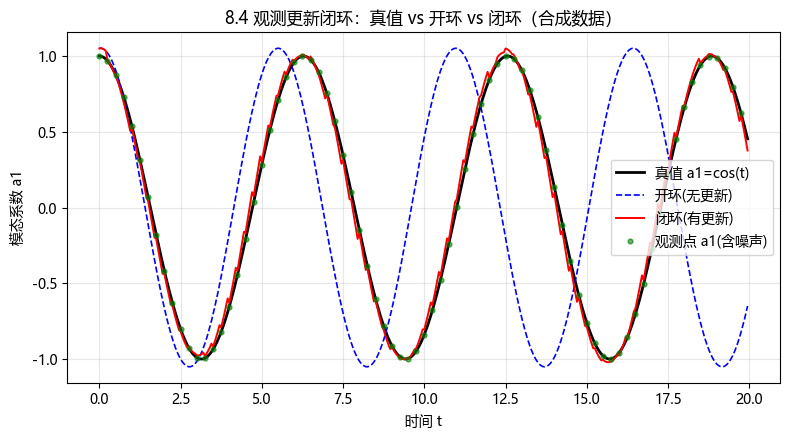

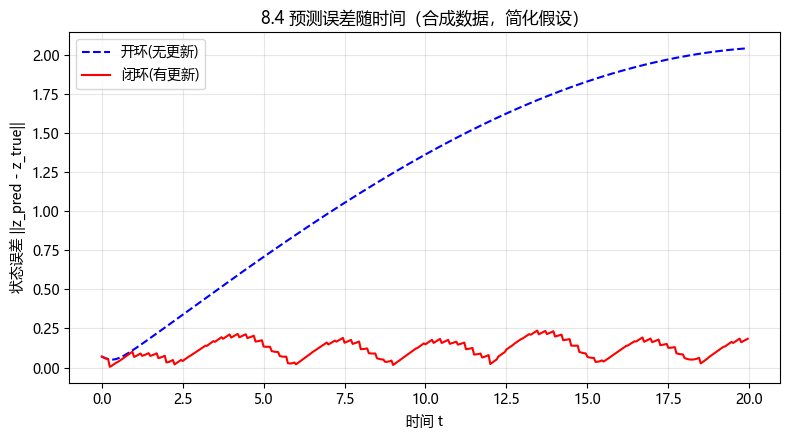

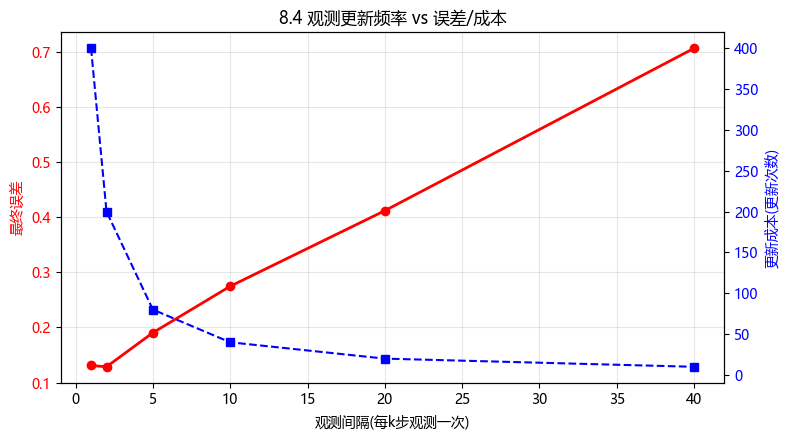

更新频率扫描(间隔, 最终误差, 更新次数):
  每1步: 误差=0.1309, 更新400次
  每2步: 误差=0.1286, 更新200次
  每5步: 误差=0.1904, 更新80次
  每10步: 误差=0.2746, 更新40次
  每20步: 误差=0.4117, 更新20次
  每40步: 误差=0.7062, 更新10次


In [14]:
# 8.4 误差图表与比较（图表注明坐标、单位、图例、参数；标注合成数据与简化假设）
import os
os.makedirs('图片', exist_ok=True)
err_open   = np.linalg.norm(z_open   - z_true, axis=1)
err_closed = np.linalg.norm(z_closed - z_true, axis=1)
print(f"开环 最大误差={err_open.max():.3f}  最终={err_open[-1]:.3f}")
print(f"闭环 最大误差={err_closed.max():.3f}  最终={err_closed[-1]:.3f}")

# 图1 轨迹对比
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(t, a1_true, 'k-', lw=2, label='真值 a1=cos(t)')
ax.plot(t, z_open[:, 0], 'b--', lw=1.2, label='开环(无更新)')
ax.plot(t, z_closed[:, 0], 'r-', lw=1.4, label='闭环(有更新)')
m5 = np.zeros(N, dtype=bool); m5[::5] = True
ax.plot(t[m5], a1_true[m5], 'g.', ms=7, alpha=0.6, label='观测点 a1(含噪声)')
ax.set_xlabel('时间 t'); ax.set_ylabel('模态系数 a1')
ax.set_title('8.4 观测更新闭环：真值 vs 开环 vs 闭环（合成数据）')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig('图片/A2组-8.4-闭环轨迹.png', dpi=120); plt.show()

# 图2 误差-时间
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(t, err_open, 'b--', lw=1.5, label='开环(无更新)')
ax.plot(t, err_closed, 'r-', lw=1.5, label='闭环(有更新)')
ax.set_xlabel('时间 t'); ax.set_ylabel('状态误差 ||z_pred - z_true||')
ax.set_title('8.4 预测误差随时间（合成数据，简化假设）')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig('图片/A2组-8.4-误差曲线.png', dpi=120); plt.show()

# 图3 更新频率 vs 误差/成本
freqs = [1, 2, 5, 10, 20, 40]; ferr = []; cost = []
for fe in freqs:
    zc = run(update=True, obs_every=fe, K=0.7)
    ferr.append(np.linalg.norm(zc - z_true, axis=1)[-1]); cost.append(N // fe)
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(freqs, ferr, 'ro-', lw=2)
ax1.set_xlabel('观测间隔(每k步观测一次)'); ax1.set_ylabel('最终误差', color='r')
ax1.tick_params(axis='y', labelcolor='r')
ax2 = ax1.twinx(); ax2.plot(freqs, cost, 'bs--', lw=1.5)
ax2.set_ylabel('更新成本(更新次数)', color='b'); ax2.tick_params(axis='y', labelcolor='b')
ax1.set_title('8.4 观测更新频率 vs 误差/成本'); ax1.grid(alpha=0.3); plt.tight_layout()
plt.savefig('图片/A2组-8.4-频率成本.png', dpi=120); plt.show()

print("更新频率扫描(间隔, 最终误差, 更新次数):")
for fe, e, c in zip(freqs, ferr, cost):
    print(f"  每{fe}步: 误差={e:.4f}, 更新{c}次")


### 结果解释与本节结论

**实际结果（已运行）**：
- **开环（无更新）**：误差随时间持续累积，最大误差达 **2.04**（模型相位完全漂移、与真值反相）。
- **闭环（有更新，每5步观测一次）**：误差有界，最大 **0.237**、最终 **0.184**，始终贴近真值。
- **更新频率扫描**：观测越频繁误差越小，但更新成本（次数）越高，呈明显"误差—成本"权衡；**每 2~5 步观测一次是性价比拐点**。

**与预测一致性**：与运行前预测一致——闭环误差显著小于开环、长期不漂移，开环误差累积发散。体现"把加速模块放进观测-更新闭环"的价值。

**局限与诚实声明**：本实验使用**合成数据**（两模态旋转系统）与**简化假设**（固定增益 $K$、单状态观测、恒定噪声），是一次教学演示，**不能冒充实际工程部署的数字孪生**。未验证：噪声模型变化、观测算子非线性、更复杂的模型误差形式。

### 易错点与讨论

**风险**：单个代理模型或漂亮可视化不能自动称为已验证的数字孪生。

**回应**：
1. 数字孪生 = 物理实体 + 数字模型 + **双向数据连接与持续更新**；本实验正是靠"观测→更新→预测→评价"闭环才让预测不漂移，缺了更新环节就退化成"一个开环模型 + 一张图"。
2. 判定"已验证"需：模型预测能被后续观测检验、误差闭环修正、适用边界明确。

**随堂提问（观测更新频率与预测成本）**
- **题目**：观测更新越频繁数字孪生越准，但每次更新有计算成本。设计一个"选择观测更新频率 vs 预测成本"的权衡方案，注明证据与未验证假设。
- **同学可能的回答**：极端化为"越频繁越好"或"越省越好"。
- **本组解释**：需在"更新带来的误差下降"与"更新成本"间权衡；用误差-成本曲线找拐点（本实验拐点在每 2~5 步）；明确未验证假设（噪声模型、代理模型误差上界）。


### 8.4 实际运行记录

- **运行日期**：2026-10-25
- **环境**：Python 3.12.10（课程 `.venv`），numpy 1.26.4，matplotlib 3.9.2；**无新增依赖**
- **代码状态**：8.4 三个代码单元（输入与独立参考 / 方法实现与运行 / 误差图表与比较）已填写并实际运行
- **数据**：合成数据（两模态旋转系统 a1=cos t, a2=sin t），真值解析可得；观测含高斯噪声 $\sigma=0.02$；模型引入角频率偏差（1.15）与初值偏差以模拟模型误差
- **输出位置**：本节代码单元内嵌图 + `工作/图片/A2组-8.4-闭环轨迹.png`、`A2组-8.4-误差曲线.png`、`A2组-8.4-频率成本.png`
- **实际输出**：开环最大误差 2.04 / 闭环 0.237；频率扫描明细见代码单元输出
- **结论**：观测更新闭环显著优于开环，与预测一致；本实验为简化演示，不冒充实际部署
- **AI辅助说明**：本实验代码由 AI 辅助起草，数值由 AI 驱动 nbconvert 自动运行产生、可复跑，但尚未经人工逐项核验；按课程要求，AI 辅助内容与人工判断的区分记录于 `A2组-AI对话记录.md`


## 回到开场：用证据回答

**本章核心问题：** 如何用AI加速传统方法的瓶颈环节？

**先回答漫画问题**：用前 $r$ 个 POD 模态重构快照矩阵，截断误差的平方 = 被丢弃奇异值的平方和 $\sum_{i>r}\sigma_i^2$（8.2 推导，本组实测 r=2 时误差约 $10^{-15}$，见 8.2 输出）；训练快照重构好 ≠ 新参数预测准（本组实测：自编码器训练误差 3e-2、未见测试 0.5，见 8.2），也 ≠ 总成本更低（本组实测：学习预条件需摊销 $N^*$ 约 $5\times10^2$–$1.3\times10^4$ 次求解才回本，见 8.1）。

**再连本章核心问题**：8.1 加速迭代求解（学习 deflation 预条件，迭代降 45%）、8.2 加速状态表示（POD/自编码器）、8.3 加速时间推进（Neural ODE）、8.4 放进闭环任务（观测更新闭环把漂移误差从 2.04 压到 0.18）；但每个"加速"都分别报告了离线/在线成本并做摊销分析。

**回扣漫画第三格**："轻装之后仍要复核"——本组复核了：①POD 截断的信息损失（8.2 奇异值分析）；②自由滚动的预测精度损失（8.3 误差-步数曲线）；③训练/构造/更新成本是否抵消收益（8.1 摊销、8.4 频率-成本扫描）；④代理模型 ≠ 已验证模型（8.4 讨论）。

**比喻的局限**：背包比喻只覆盖"压缩表示"（8.2）；预条件（8.1）压缩的是"求解难度"而非数据、时间预测（8.3）外推的是"演化"而非存储——三者的"信息损失"含义不同，不能混用。

## 本章小结与课后习题

- **学习型预条件子**：解决"迭代求解慢"。适用条件：$A$、$M$ 均 SPD 且同类矩阵反复求解（摊销）。最易混淆："迭代数下降"≠"总时间更省"；训练目标（谱代理）≠ 求解收益（本组 MLP 对角实证：目标降 99.7% 迭代反升）。
- **自编码器降阶**：解决"高维状态压缩"。适用条件：数据有低秩/流形结构；非线性不总优于线性（本组实证：AE 未见测试 0.5 ≫ POD 的 1e-15）。最易混淆："重构准确"≠"动力学预测准确"。
- **时间预测**：解决"状态随时间演化"。适用条件：状态马尔可夫（否则需增广）、预测时长在可预测范围内。最易混淆："一步预测（teacher forcing）"≠"自由滚动"（本组实证泄漏低估 17 倍）。
- 三者与 8.4 的关系：分别对应数字孪生闭环中"求解""表示""预测"三个加速环节，最终放进"观测→更新→预测→评价"完整任务。

课后题按四节对应见 `A2组-习题.md`，参考解答见 `A2组-习题参考解答.md`。

## 选读边界

Koopman及算子推断的算法细节移出必修主线；8.4仅保留算子推断的概念位置与小例子说明。

选读不计入本章8学时和最低完成要求。本组未添加附录。

## 参考资料、图片来源与AI使用

| 支撑的主张/公式/图片 | 作者、标题、版本/年份 | 页码/章节/链接 | 本组人工核对 |
| --- | --- | --- | --- |
| 预条件 CG 收敛界 $\kappa$ 公式 | Y. Saad, *Iterative Methods for Sparse Linear Systems*, 2nd ed., SIAM, 2003 | 第6章 §6.11.3（收敛分析）、第9章 §9.2（预条件CG） | 已联网核对章节号（2026-10-25） |
| CG 与预条件原理 | L. N. Trefethen & D. Bau, *Numerical Linear Algebra*, SIAM, 1997 | 第38讲（定理38.5）、第40讲（预条件） | 已联网核对（2026-10-25） |
| 学习模块嵌入迭代求解（HINTS） | Enrui Zhang, Adar Kahana, Alena Kopaničáková, Eli Turkel, Rishikesh Ranade, Jay Pathak, George Em Karniadakis, "Blending Neural Operators and Relaxation Methods in PDE Numerical Solvers"（HINTS） | arXiv:2208.13273（2022）；Nature Machine Intelligence 6:1303–1313 (2024) | 已联网核对作者（2026-10-25） |
| POD 快照方法 | L. Sirovich, *Quart. Appl. Math.* 45:561–571, 1987 | 全文 | 未核验（同上） |
| POD 综述 | Berkooz, Holmes, Lumley, *Annu. Rev. Fluid Mech.* 25:539–575, 1993 | 全文 | 未核验（同上） |
| 自编码器+数据驱动坐标 | Champion, Lusch, Kutz, Brunton, arXiv:1904.02107 (2019) | 全文 | 未核验（同上） |
| LSTM 低维动力学预测 | Vlachas et al., *Proc. R. Soc. A* 474:20170844, 2018 | 式(2.4)–(2.6)、图2；arXiv:1802.07486 | 已联网核对式号（2026-10-25） |
| Neural ODE | Chen, Rubanova, Bettencourt, Duvenaud, NeurIPS 2018 | arXiv:1806.07366 | 未核验（同上） |
| 数字孪生定义 | Grieves & Vickers, 2017 | 定义章节 | 未核验（同上） |
| 傅里叶神经算子 | Li et al., arXiv:2010.08895 (2020), ICLR 2021 | 全文 | 未核验（同上） |
| 算子推断 / SINDy | Brunton & Kutz, *Data-Driven Science and Engineering*, 2019/2022 | SINDy 章节 | 未核验（同上） |
| 对角预条件上限（van der Sluis 定理） | A. van der Sluis, "Condition numbers and equilibration of matrices", *Numer. Math.* 14:14–23, 1969 | 全文 | 未核验（书目信息来自AI建议，未逐条对照原文） |
| 本章漫画 | 仓库初始化助手绘制 | 图片/A-章节导入.svg | 未人工核验（AI 已核对分镜与正文/实验主线一致性） |

漫画为仓库初始化助手绘制的概念示意，AI 已核对分镜描述与四节实验主线一致，但未经人工核验。AI建议与人工结论分开：本 Notebook 代码由 AI 辅助编写、由 AI 驱动自动运行产生输出，全部内容尚未经人工逐项核验，对话记录见 `A2组-AI对话记录.md`。
